The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.


The dataset in this lab contains 15,000 rows and 10 columns for the variables listed below.

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

In [210]:
#        stakeholders: Salifort Motors HR, data analysts
#             problem: losing employees, what is the cause?
#initial observations: need to encode dep and salary, 'left' is dependent variable.
#           resources: documentation from https://pandas.pydata.org/docs/reference/ and past projects
#              ethics: so far, no considerations

In [211]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\brett\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [212]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score,\
f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from xgboost import plot_importance
import seaborn as sns

In [213]:
# Load dataset into a dataframe
from pathlib import Path
import os
file_path = str(Path(os.getcwd()) / "dataset.csv")
df0 = pd.read_csv(file_path)

# Display first few rows of the dataframe
df0.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [214]:
# Gather basic information about the data
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [215]:
# Gather descriptive statistics about the data

df0.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [216]:
# Display all column names
old_names=df0.columns
new_names=list(map(lambda x: x.lower(),old_names))
new_names[0]='satisfaction'
new_names[1]='eval'
new_names[2]='num_projects'
new_names[3]='avg_monthly_hours'
new_names[4]='time_w_comp'
new_names[7]='promotion_last_5_years'
new_names[8]='dept'
new_names

['satisfaction',
 'eval',
 'num_projects',
 'avg_monthly_hours',
 'time_w_comp',
 'work_accident',
 'left',
 'promotion_last_5_years',
 'dept',
 'salary']

In [217]:
# Rename columns as needed
name_key = dict(zip(old_names, new_names))
df0.rename(columns=name_key,inplace=True)
# Display all column names after the update
df0.columns

Index(['satisfaction', 'eval', 'num_projects', 'avg_monthly_hours',
       'time_w_comp', 'work_accident', 'left', 'promotion_last_5_years',
       'dept', 'salary'],
      dtype='str')

In [218]:
# Check for missing values
df0.isna().sum()

satisfaction              0
eval                      0
num_projects              0
avg_monthly_hours         0
time_w_comp               0
work_accident             0
left                      0
promotion_last_5_years    0
dept                      0
salary                    0
dtype: int64

In [219]:
# Check for duplicates
df0.duplicated().sum()

np.int64(3008)

In [220]:
# Inspect some rows containing duplicates
df0[df0.duplicated()]

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [221]:
# Drop duplicates and save resulting dataframe  in place
df0.drop_duplicates(keep='first',ignore_index=True,inplace=True)

# Display first few rows of new dataframe
df0.duplicated().sum()

np.int64(0)

In [222]:
df0.iloc[395:398]

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
395,0.45,0.46,2,128,3,0,1,0,sales,low
396,0.09,0.79,6,293,5,0,1,0,sales,low
397,0.87,0.83,4,265,6,0,1,0,sales,low


In [223]:
sns.set_style("whitegrid")

<Axes: xlabel='time_w_comp'>

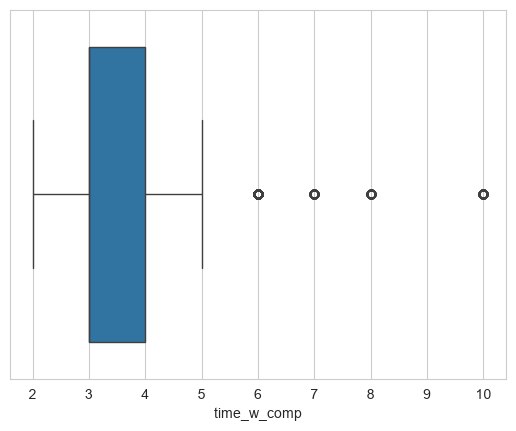

In [224]:
# Create a boxplot to visualize distribution of `time_spend_company` and detect any outliers
sns.boxplot(data=df0, x='time_w_comp')

<Axes: xlabel='time_w_comp'>

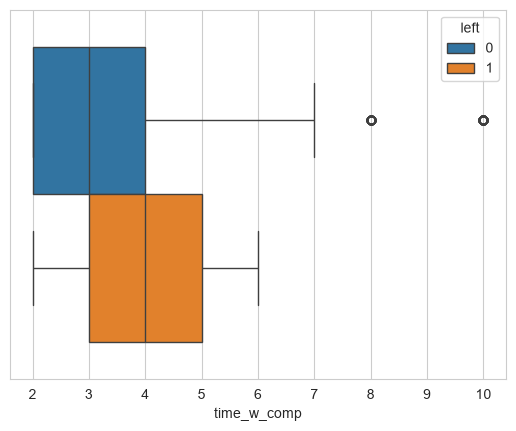

In [225]:
#left is relevant to check
sns.boxplot(data=df0, x='time_w_comp',hue='left')

In [226]:
#most who haven't left haven't been with company very long - may indicate burnout culture

In [227]:
#different types of data
cont = ['satisfaction', 'eval']
discrete = ['num_projects', 'avg_monthly_hours', 'time_w_comp']
binary = ['work_accident', 'promotion_last_5_years']
categorical = ['dept', 'salary']

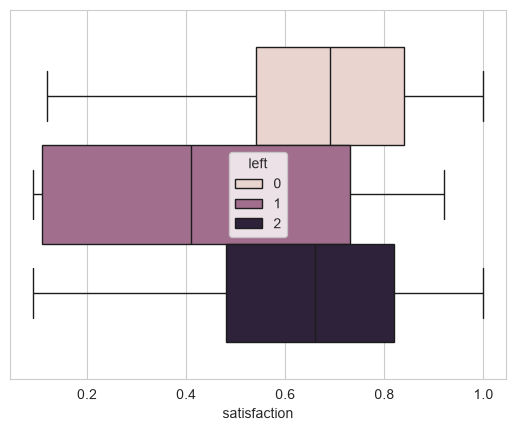

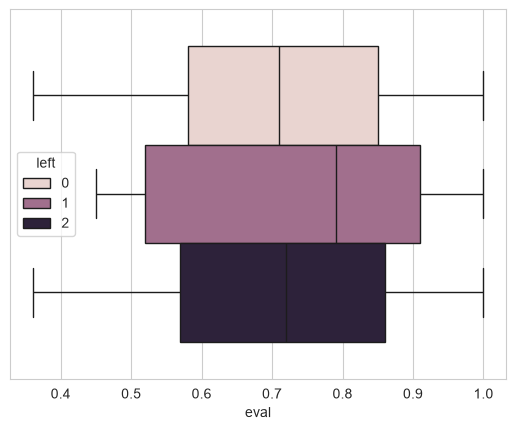

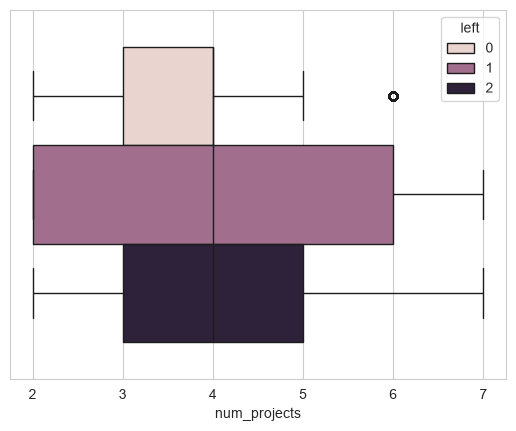

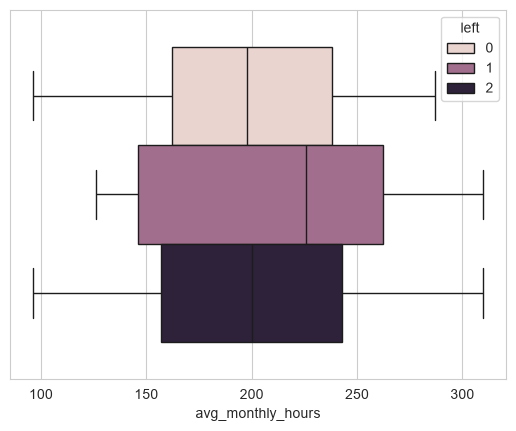

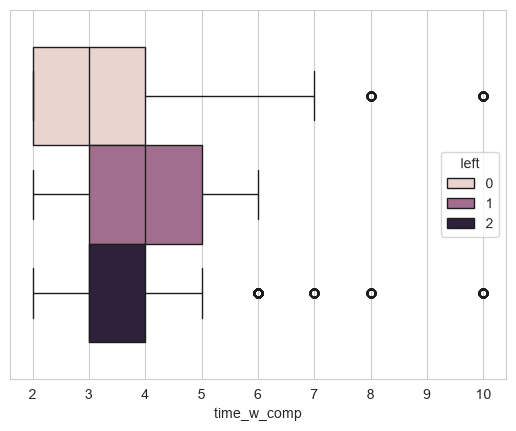

In [228]:
# Create a boxplots to visualize distribution of different columns
# want to see left, stayed, and overall (represented with 2)
to_box_plot_cols=cont + discrete
df_both = df0.copy()
df_both['left'] = 2
df_combined = pd.concat([df0, df_both], ignore_index=True)
for i in to_box_plot_cols:
    plt.figure(i)
    sns.boxplot(data=df_combined, x=i,hue='left')

In [229]:
df0.dtypes

satisfaction              float64
eval                      float64
num_projects                int64
avg_monthly_hours           int64
time_w_comp                 int64
work_accident               int64
left                        int64
promotion_last_5_years      int64
dept                          str
salary                        str
dtype: object

In [230]:
#satisfaction looks like effects leaving or not - seems obvious
#fewer projects - fewer left, but also very few projects left more
#avg of 4.3 weeks/month, meaning typical full time job is 172Hr/mon. (with no vacation/sick days/personal days/etc.)
#looks like most employees working even more than full time with no time off, avg is ~200

In [231]:
#get probabilities of other columns
to_count_cols=binary + categorical
for i in to_count_cols:
    print(df0[i].value_counts())
    print(df0[i].value_counts(normalize=True))

work_accident
0    10141
1     1850
Name: count, dtype: int64
work_accident
0    0.845718
1    0.154282
Name: proportion, dtype: float64
promotion_last_5_years
0    11788
1      203
Name: count, dtype: int64
promotion_last_5_years
0    0.983071
1    0.016929
Name: proportion, dtype: float64
dept
sales          3239
technical      2244
support        1821
IT              976
RandD           694
product_mng     686
marketing       673
accounting      621
hr              601
management      436
Name: count, dtype: int64
dept
sales          0.270119
technical      0.187140
support        0.151864
IT             0.081394
RandD          0.057877
product_mng    0.057210
marketing      0.056125
accounting     0.051789
hr             0.050121
management     0.036361
Name: proportion, dtype: float64
salary
low       5740
medium    5261
high       990
Name: count, dtype: int64
salary
low       0.478692
medium    0.438746
high      0.082562
Name: proportion, dtype: float64


In [232]:
#very few promotions

In [233]:
# Determine the number of rows containing outliers
q1=df0['time_w_comp'].quantile(0.25)
q3=df0['time_w_comp'].quantile(0.75)
iqr=q3-q1
l_range=q1-1.5*iqr

u_range=q3+1.5*iqr
dfoutlier=df0[(df0['time_w_comp']<l_range) | (df0['time_w_comp']>u_range)]
dfoutlier.head()

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
1,0.80,0.86,5,262,6,0,1,0,sales,medium
17,0.78,0.99,4,255,6,0,1,0,sales,low
34,0.84,0.87,4,246,6,0,1,0,hr,low
47,0.57,0.70,3,273,6,0,1,0,support,low
67,0.90,0.98,4,264,6,0,1,0,product_mng,medium


In [234]:
print(len(dfoutlier),len(df0))

824 11991


In [235]:
#~1% are outliers, not worth worrying about

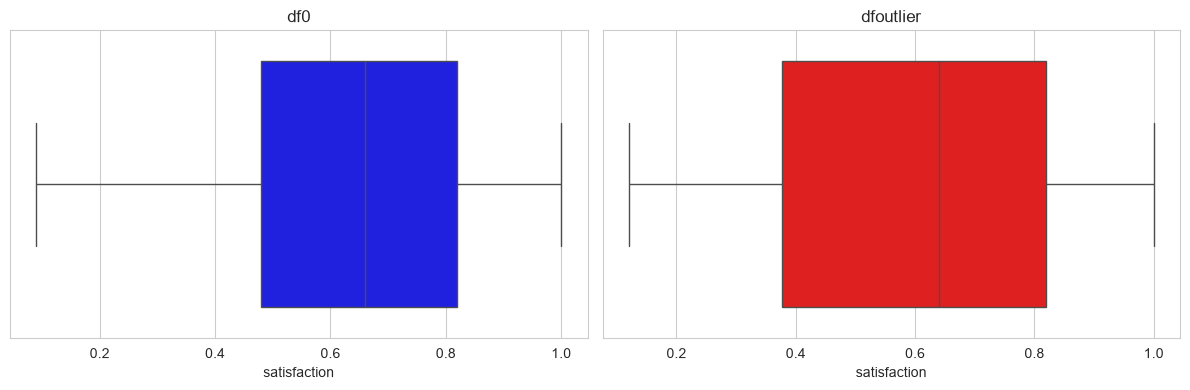

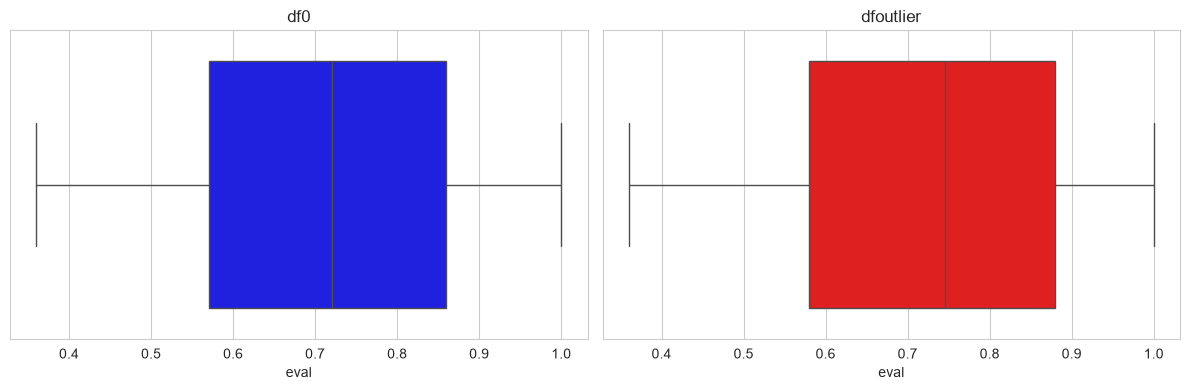

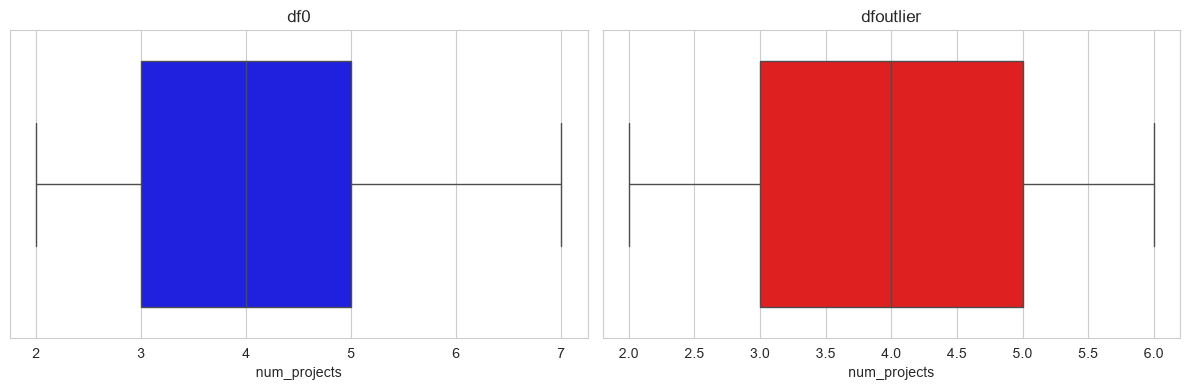

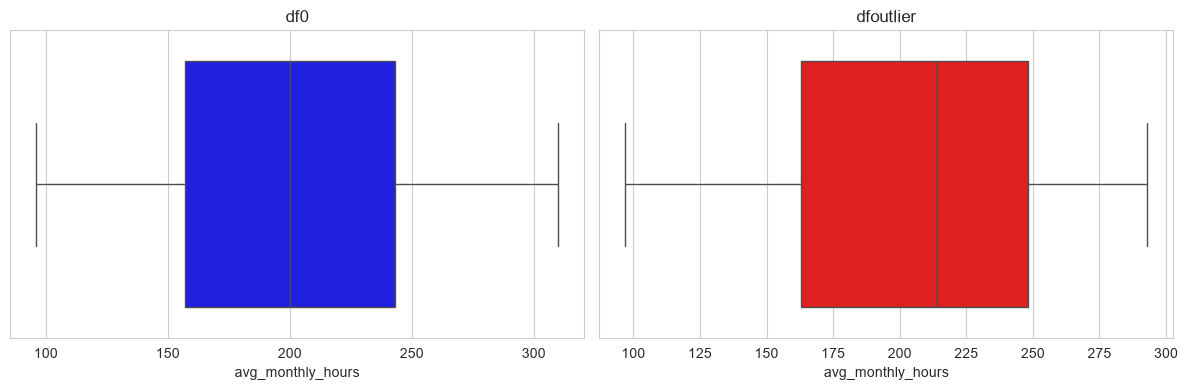

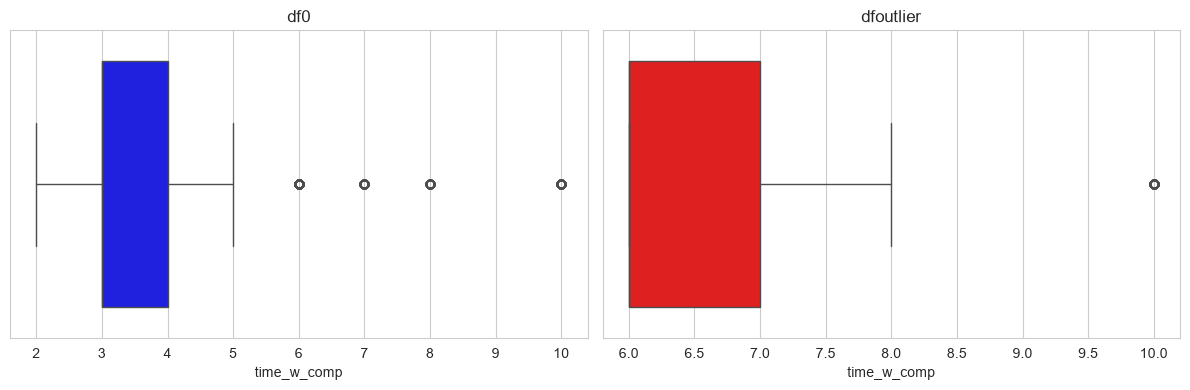

In [236]:
# Create a boxplot to visualize distribution of outlier subset, and compare to general
to_box_plot_cols=cont + discrete
for i in to_box_plot_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(data=df0, x=i, ax=axes[0], color="blue")
    axes[0].set_title("df0")
    sns.boxplot(data=dfoutlier, x=i, ax=axes[1], color="red")
    axes[1].set_title("dfoutlier")
    plt.tight_layout()
    plt.show()

In [237]:
#relationships b/w vars: workload seems correlated with satisfaction/retention

#distributions: population that left co. had higher avg. monthly hours, higher evals, and lower satisfaction

#EDA purpose: determine if data is of right type to use with models, clean data, make relevant

#transformations: convert low, medium, and high into 1,2,3 (labels have ordered property)

#resources: https://seaborn.pydata.org/ and past projects

#ethics: can advocate for better treatment of employees

In [238]:
# Get numbers of people who left vs. stayed
print(df0['left'].value_counts())
# Get percentages of people who left vs. stayed
print(df0['left'].value_counts(normalize=True))

left
0    10000
1     1991
Name: count, dtype: int64
left
0    0.833959
1    0.166041
Name: proportion, dtype: float64


In [239]:
#general leaving ~15%, so if category has >15% leaving, of interest

In [240]:
df0.dtypes

satisfaction              float64
eval                      float64
num_projects                int64
avg_monthly_hours           int64
time_w_comp                 int64
work_accident               int64
left                        int64
promotion_last_5_years      int64
dept                          str
salary                        str
dtype: object

satisfaction
eval


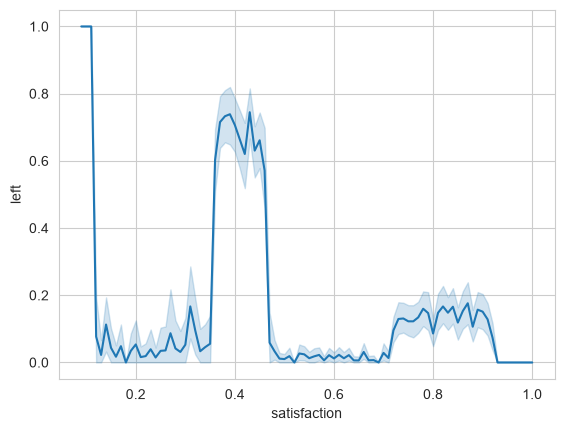

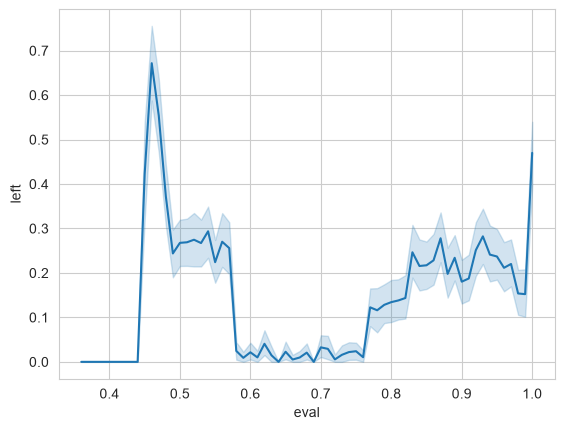

In [241]:
import matplotlib.pyplot as plt
for i in range(len(cont)):
    print(cont[i])
    plt.figure(i)
    sns.lineplot(data=df0,x=cont[i],y='left')

In [242]:
#looks weird, why are there big gaps in eval and satisfaction?

satisfaction
eval


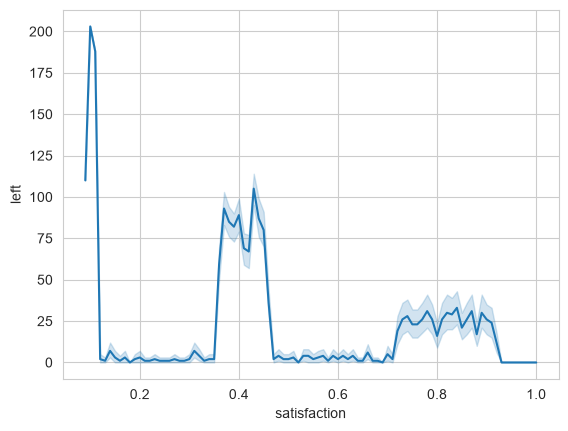

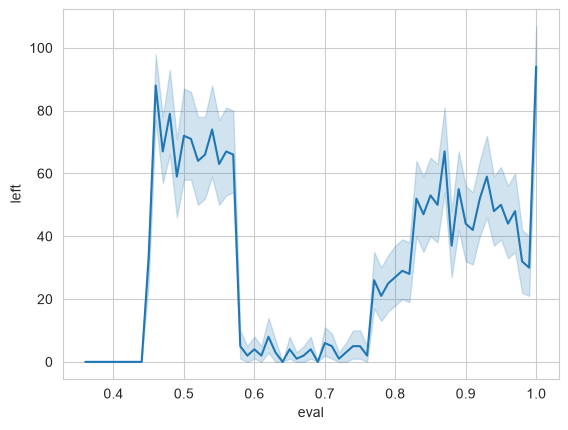

In [243]:
import matplotlib.pyplot as plt
for i in range(len(cont)):
    print(cont[i])
    plt.figure(i)
    sns.lineplot(data=df0,x=cont[i],y='left',estimator='sum')

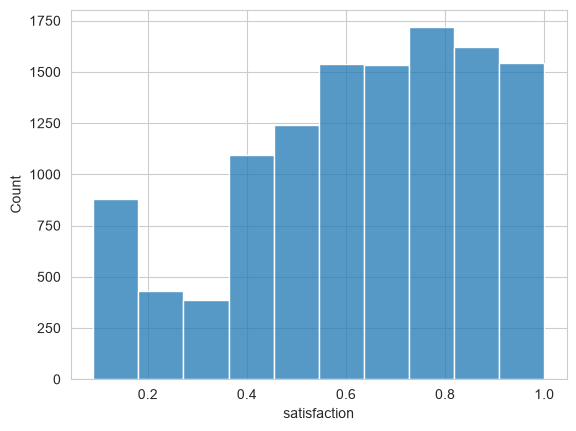

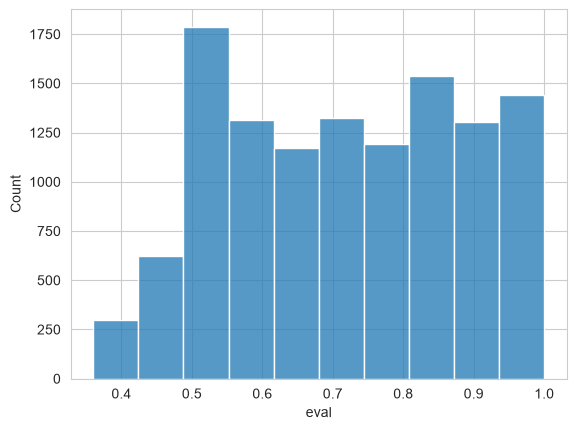

In [244]:
for i in cont:
    plt.figure(i)
    sns.histplot(data=df0,x=i,bins=10)

In [245]:
#"gaps" in leaving from eval 0.6-0.8 and satisfaction 0.5-0.7 (for example)? Maybe missing entries/corrupted data, check with company
#roughly, higher satisfaction leads to higher retention. Eval has smaller effect

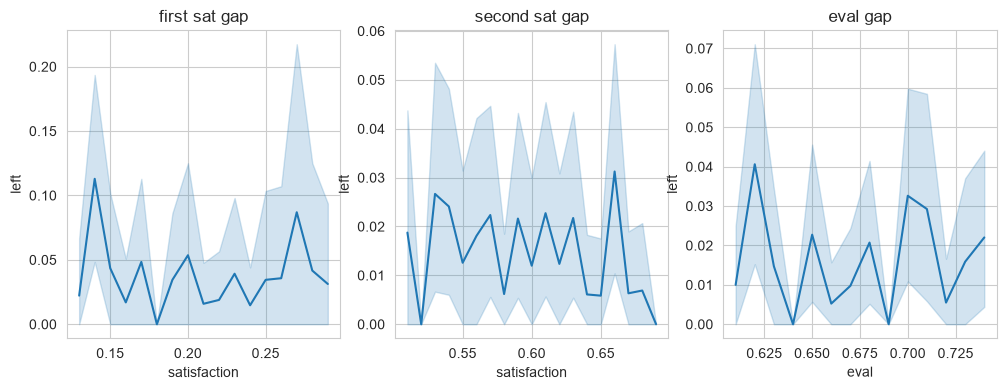

In [246]:
#take closer look at "gaps" in eval and satisfaction
df0_sat_gap1=df0[((df0['satisfaction']>0.125) & (df0['satisfaction']<0.3))]
df0_sat_gap2=df0[((df0['satisfaction']>0.5) & (df0['satisfaction']<0.7))]
df0_eval_gap=df0[(df0['eval']>0.6) & (df0['eval']<0.75)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.lineplot(data=df0_sat_gap1,x='satisfaction',y='left', ax=axes[0])
axes[0].set_title("first sat gap")
sns.lineplot(data=df0_sat_gap2,x='satisfaction',y='left', ax=axes[1])
axes[1].set_title("second sat gap")
sns.lineplot(data=df0_eval_gap,x='eval',y='left', ax=axes[2])
axes[2].set_title("eval gap")
plt.show()

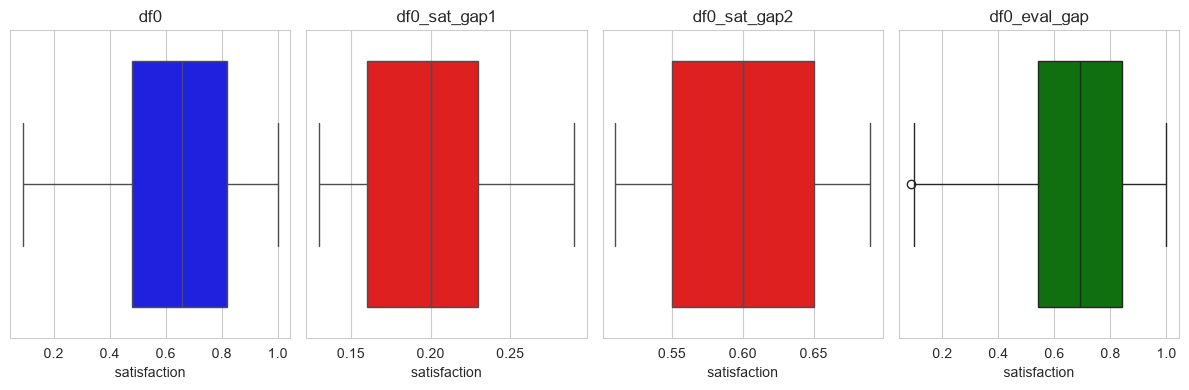

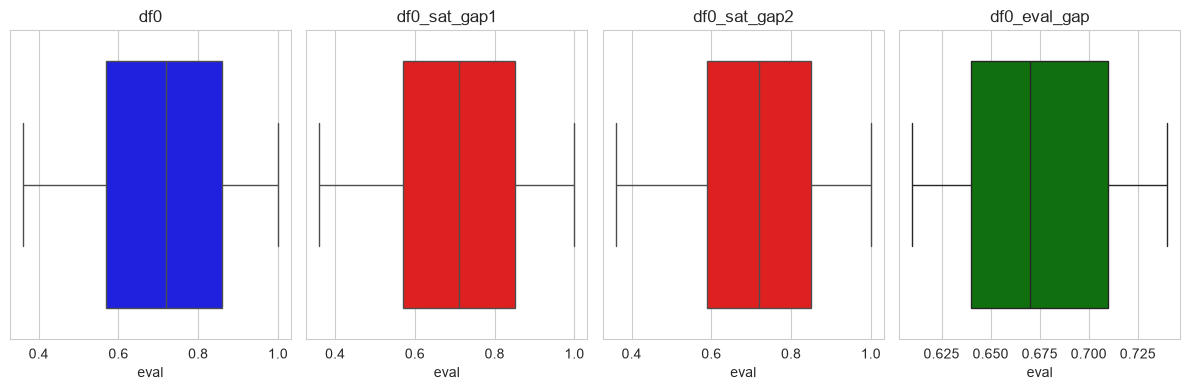

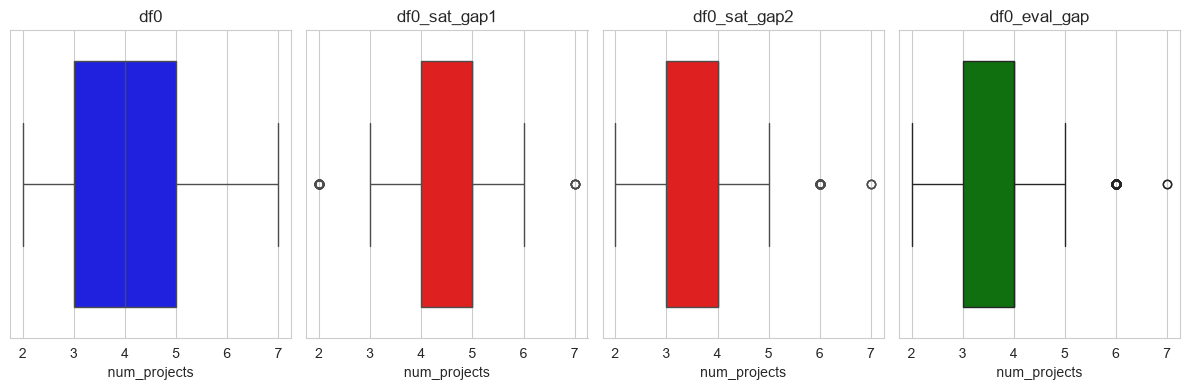

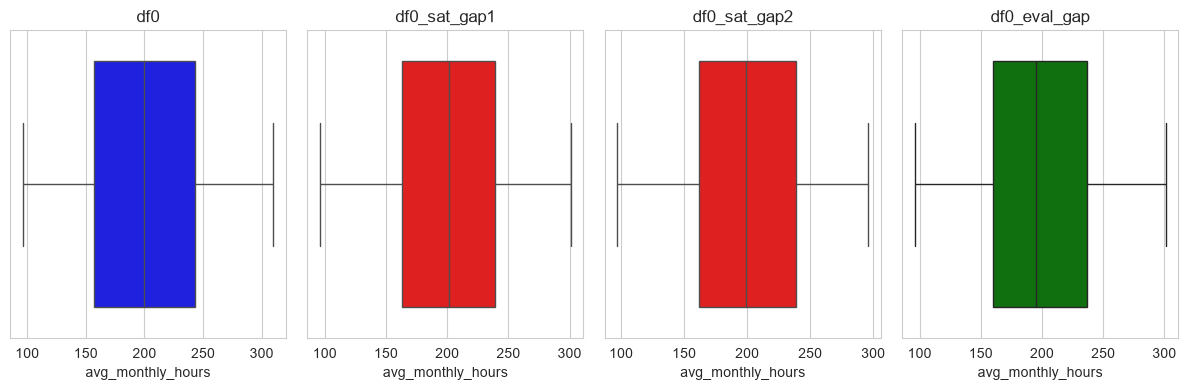

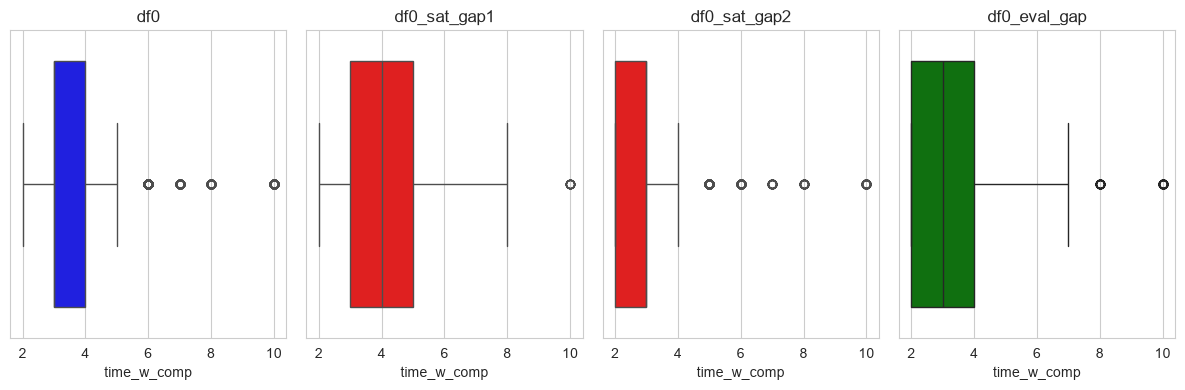

In [247]:
for i in to_box_plot_cols:
    fig, axes = plt.subplots(1, 4, figsize=(12, 4))
    sns.boxplot(data=df0, x=i, ax=axes[0], color="blue")
    axes[0].set_title("df0")
    sns.boxplot(data=df0_sat_gap1, x=i, ax=axes[1], color="red")
    axes[1].set_title("df0_sat_gap1")
    sns.boxplot(data=df0_sat_gap2, x=i, ax=axes[2], color="red")
    axes[2].set_title("df0_sat_gap2")
    sns.boxplot(data=df0_eval_gap, x=i, ax=axes[3], color="green")
    axes[3].set_title("df0_eval_gap")
    plt.tight_layout()
    plt.show()

In [248]:
#the second sat gap and eval gap have fewer projects, possible explanation for higher retention?
#could just be because most are not long time employees

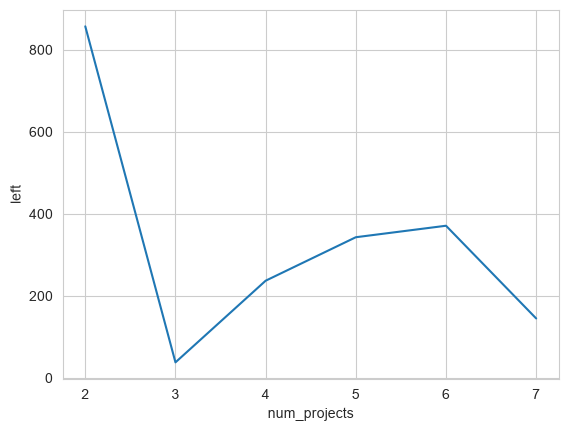

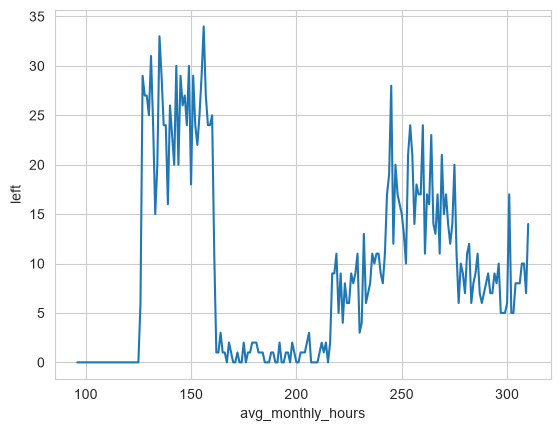

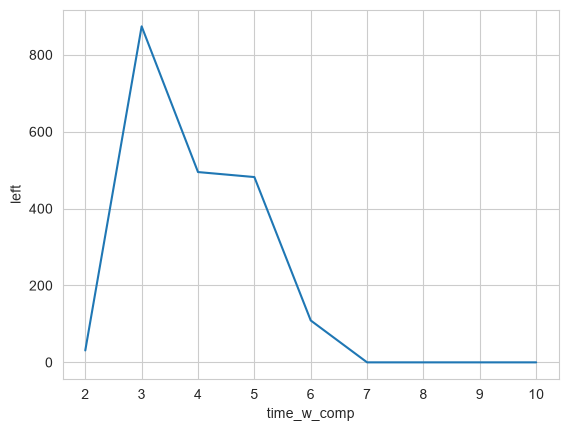

In [249]:
for i in discrete:
    s_dis=df0.groupby(i,as_index=False).sum()
    plt.figure(i)
    sns.lineplot(data=s_dis,x=i,y='left')

In [250]:
#same "gap" problem for 160-220 monthly hrs.

Text(0.5, 1.0, 'Monthly hours by last evaluation score')

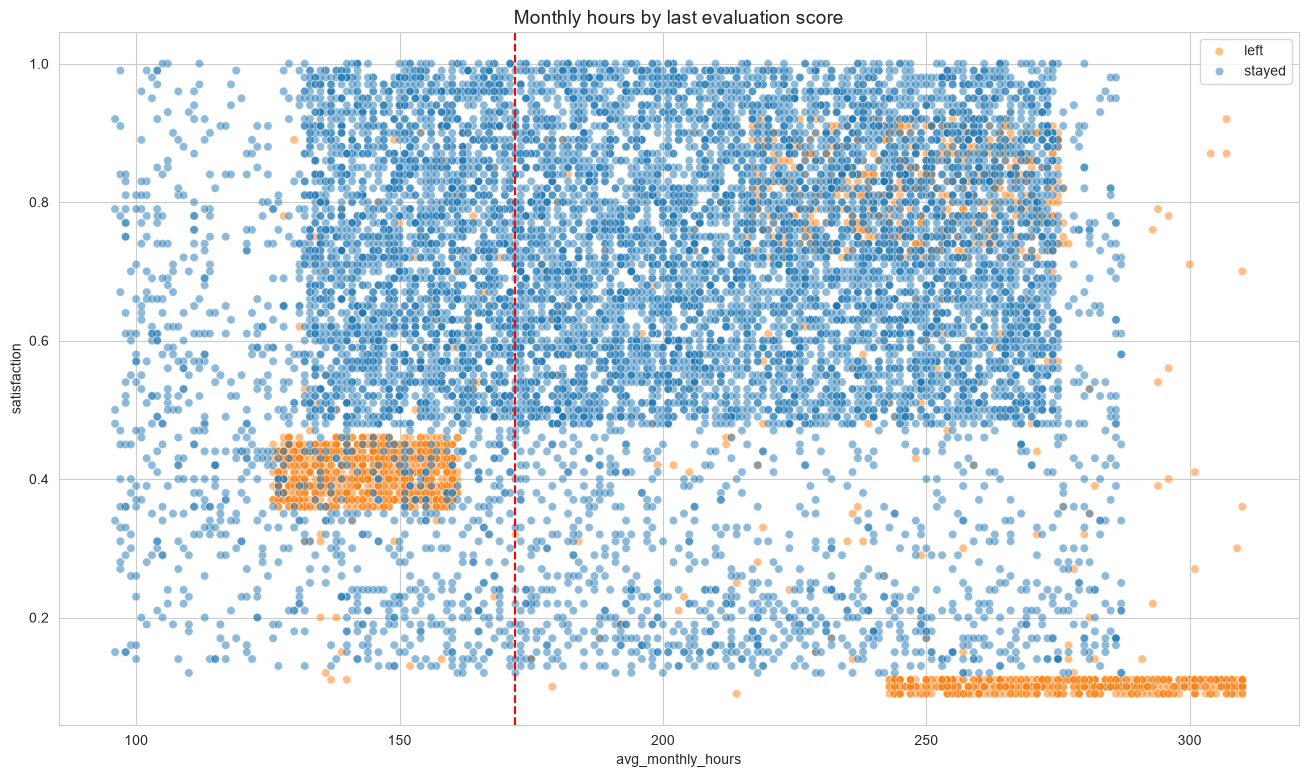

In [251]:
plt.figure(figsize=(16, 9))
sns.scatterplot(data=df0, x='avg_monthly_hours', y='satisfaction', hue='left', alpha=0.5)
plt.axvline(x=172, color='red', label='172 hrs./mo.', ls='--')
plt.legend(labels=['left', 'stayed'])
plt.title('Monthly hours by last evaluation score', fontsize='14')

In [252]:
#can clearly see three groups that left, sub 0.1 satisfaction and 240-320 hrs/mon., 0.3-0.5 satisfaction and 125-160 hrs/mon., and sup 0.7 satisfaction and 220-275 hrs/mon.

In [253]:
df0.dtypes

satisfaction              float64
eval                      float64
num_projects                int64
avg_monthly_hours           int64
time_w_comp                 int64
work_accident               int64
left                        int64
promotion_last_5_years      int64
dept                          str
salary                        str
dtype: object

In [254]:
#for future work, what does data look like when dropping sat, eval, and monthly hour "gaps"?
df_No_gaps=df0[((df0['satisfaction']>0.125) & (df0['satisfaction']<0.3)) | ((df0['satisfaction']>0.5) & (df0['satisfaction']<0.7)) | ((df0['eval']>0.6) & (df0['eval']<0.75)) | ((df0['eval']>0.6) & (df0['eval']<0.75))]

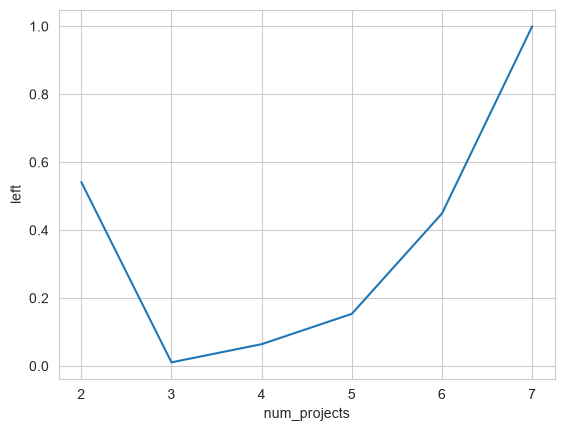

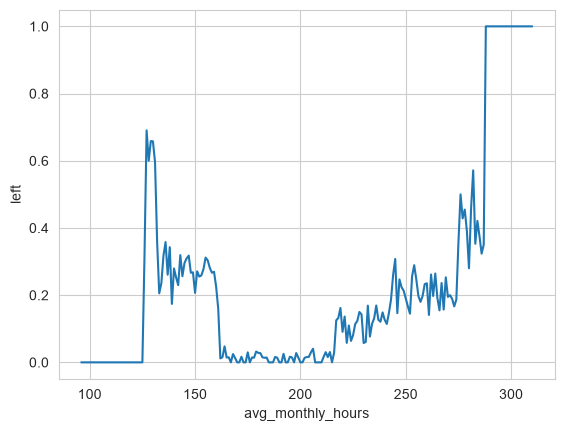

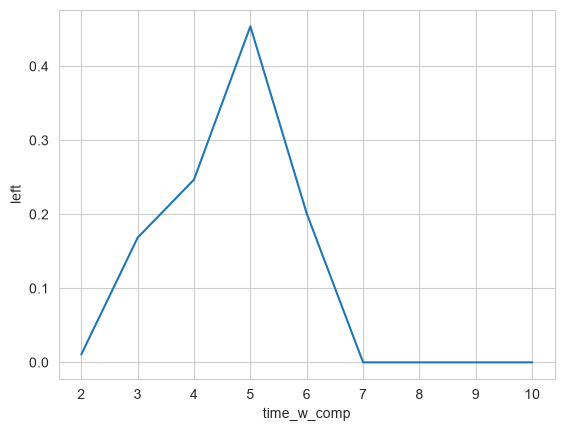

In [255]:
for i in range(len(discrete)):
    s_dis=df0.groupby(discrete[i],as_index=False)['left'].mean()
    plt.figure(i)
    sns.lineplot(data=s_dis,x=discrete[i],y='left')

In [256]:
#people who are not planning on staying don't take many projects (2) then leave, people who are overburdened leave (3 projects is sweet spot)
#avg monthly hours seems related to leaving, again weird blank stay spot from ~160-225
#most people leave after 5 years with company

In [257]:
df0.groupby(binary[0])['left'].value_counts(normalize=True)

work_accident  left
0              0       0.814022
               1       0.185978
1              0       0.943243
               1       0.056757
Name: proportion, dtype: float64

In [258]:
#more likely to stay after work accident

In [259]:
df0.groupby(binary[1])['left'].value_counts(normalize=True)

promotion_last_5_years  left
0                       0       0.831778
                        1       0.168222
1                       0       0.960591
                        1       0.039409
Name: proportion, dtype: float64

In [260]:
#being promoted makes it more likely to stay

dept
salary


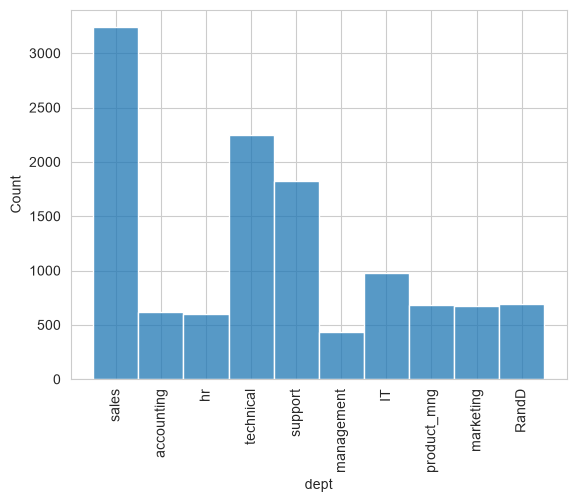

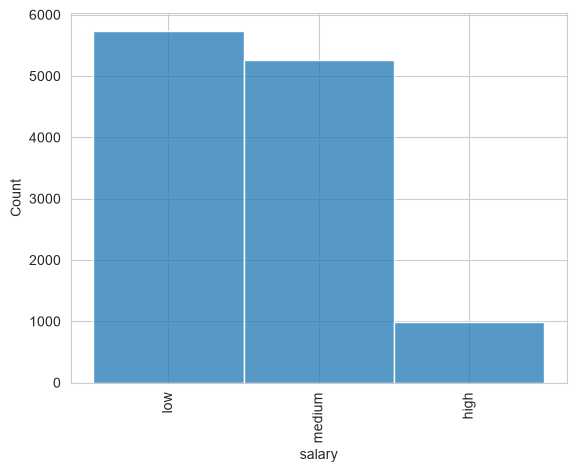

In [261]:
for i in range(len(categorical)):
    print(categorical[i])
    plt.figure(i)
    sns.histplot(data=df0,x=categorical[i])
    plt.xticks(rotation=90)

In [262]:
m_cat=df0.groupby(categorical[0],as_index=False)['left'].mean()
m_cat

,dept,left
0,IT,0.161885
1,RandD,0.122478
2,accounting,0.175523
3,hr,0.188020
4,management,0.119266
5,marketing,0.166419
6,product_mng,0.160350
7,sales,0.169805
8,support,0.171334
9,technical,0.173797


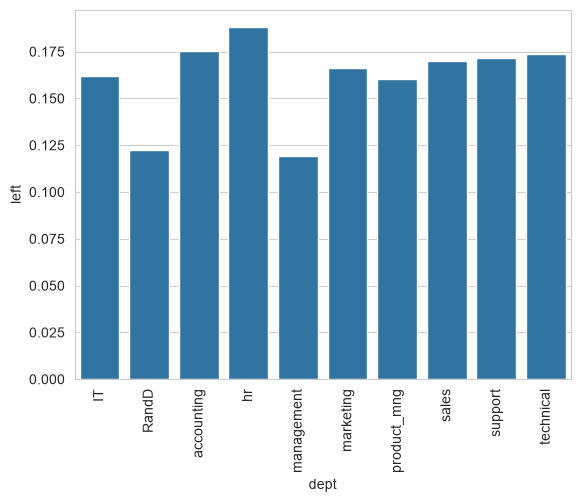

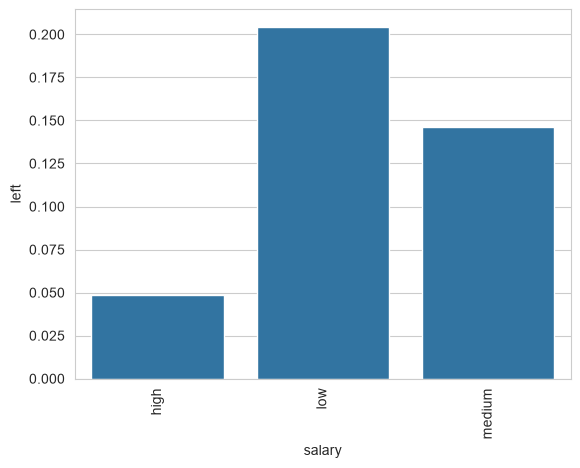

In [263]:
for i in range(len(categorical)):
    m_cat=df0.groupby(categorical[i],as_index=False)['left'].mean()
    plt.figure(i)
    sns.barplot(data=m_cat,x=categorical[i],y='left')
    plt.xticks(rotation=90)

In [264]:
#looks like no department relation
#looks like low is most likely to leave, high salary least likely

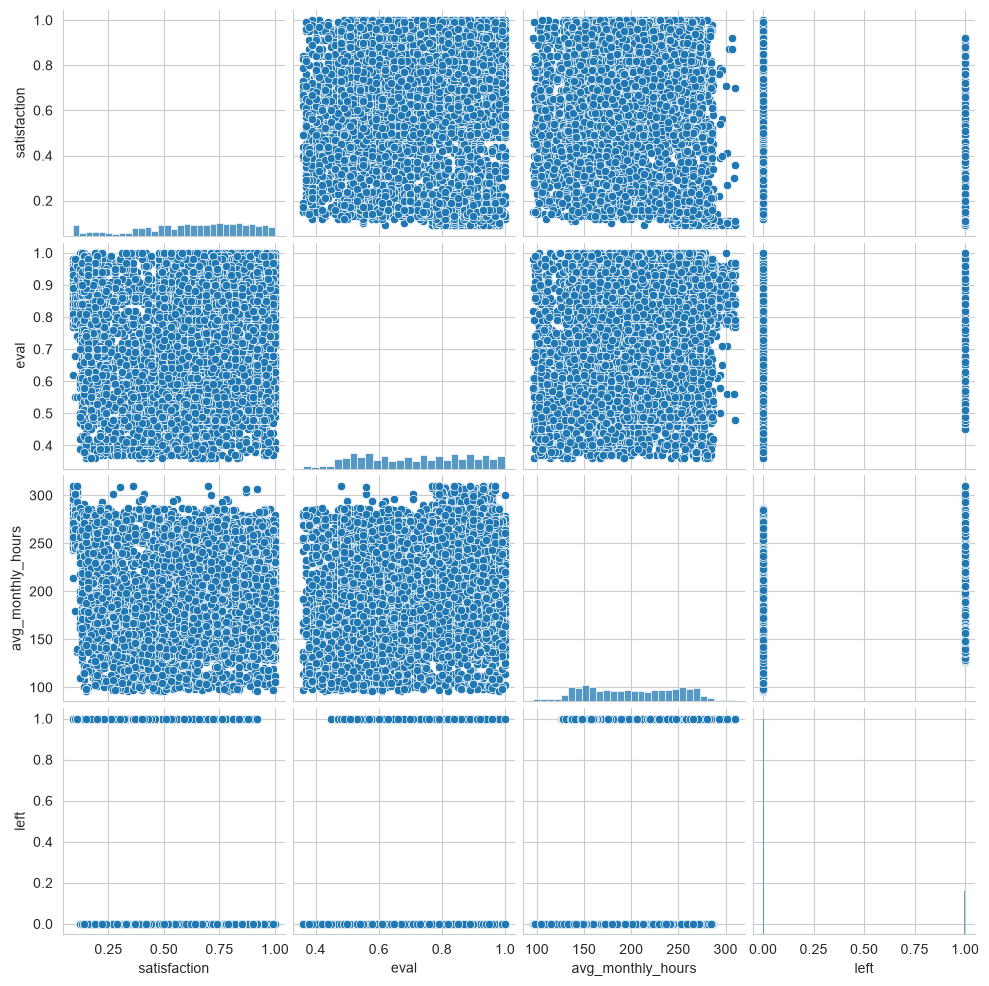

In [265]:
#look for relations between continuous, independent variables
sns.pairplot(df0[['satisfaction','eval','avg_monthly_hours','left']])

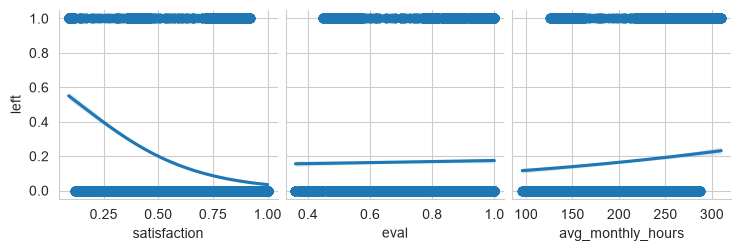

In [266]:
#check relationship b/w continuous and left
sns.pairplot(df0,x_vars=['satisfaction','eval','avg_monthly_hours'],y_vars=['left'],kind="reg",plot_kws={"logistic": True})


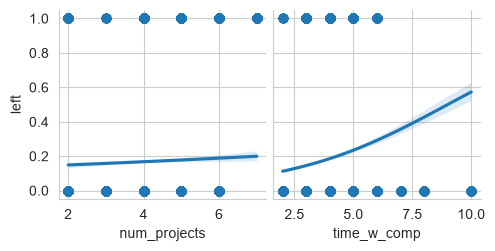

In [267]:
#check discrete variables
sns.pairplot(df0,x_vars=['num_projects','time_w_comp'],y_vars=['left'],kind="reg",plot_kws={"logistic": True})

<Axes: xlabel='num_projects', ylabel='left'>

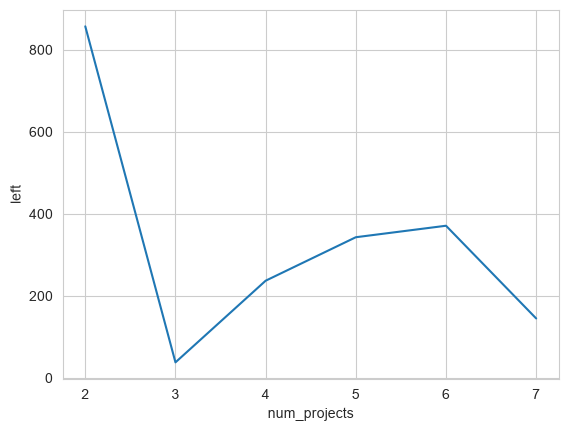

In [268]:
sum_left=df0.groupby('num_projects',as_index=False).sum()
sum_left
sns.lineplot(data=sum_left,x='num_projects',y='left')

<Axes: xlabel='num_projects', ylabel='left'>

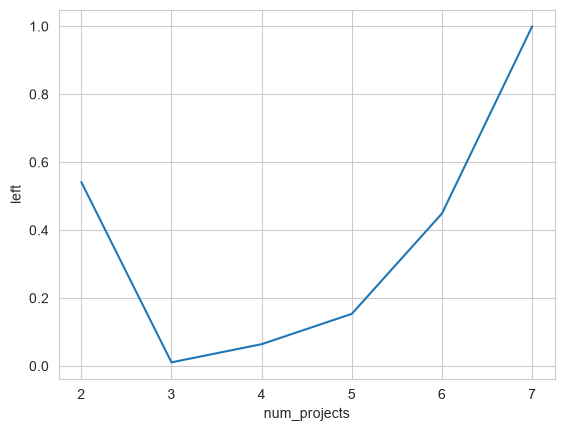

In [269]:

m_left=df0.groupby('num_projects',as_index=False)['left'].mean()
m_left
sns.lineplot(data=m_left,x='num_projects',y='left')

<Axes: xlabel='time_w_comp', ylabel='left'>

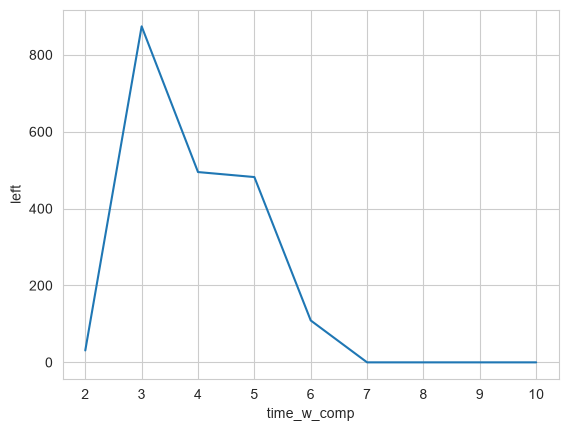

In [270]:
sum_left=df0.groupby('time_w_comp',as_index=False)['left'].sum()
sum_left
sns.lineplot(data=sum_left,x='time_w_comp',y='left')

<Axes: xlabel='time_w_comp', ylabel='left'>

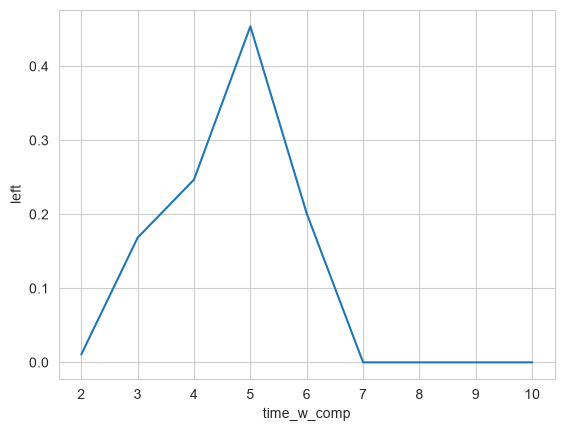

In [271]:
m_left=df0.groupby('time_w_comp',as_index=False)['left'].mean()
m_left
sns.lineplot(data=m_left,x='time_w_comp',y='left')

In [352]:
df0.columns

Index(['satisfaction', 'eval', 'num_projects', 'avg_monthly_hours',
       'time_w_comp', 'work_accident', 'left', 'promotion_last_5_years',
       'dept', 'salary'],
      dtype='str')

In [354]:
df0[df0['promotion_last_5_years']==0]

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
11980,0.90,0.76,3,255,7,0,0,0,product_mng,low
11981,0.49,0.49,4,212,7,0,0,0,product_mng,medium
11982,0.60,0.53,2,235,7,0,0,0,IT,medium
11983,0.62,0.85,3,237,3,1,0,0,IT,medium


<Axes: xlabel='time_w_comp', ylabel='left'>

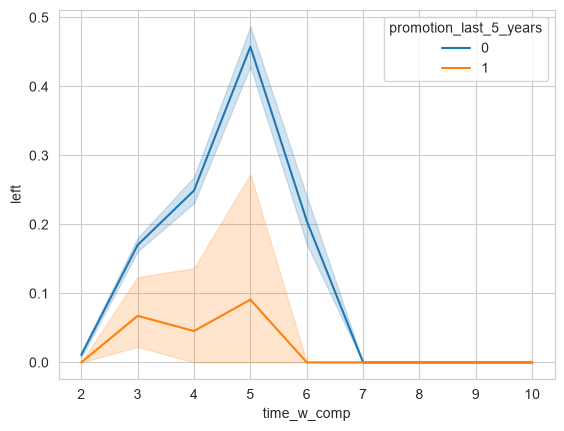

In [358]:
sns.lineplot(data=df0,x='time_w_comp',y='left',hue='promotion_last_5_years')

<Axes: xlabel='time_w_comp', ylabel='left'>

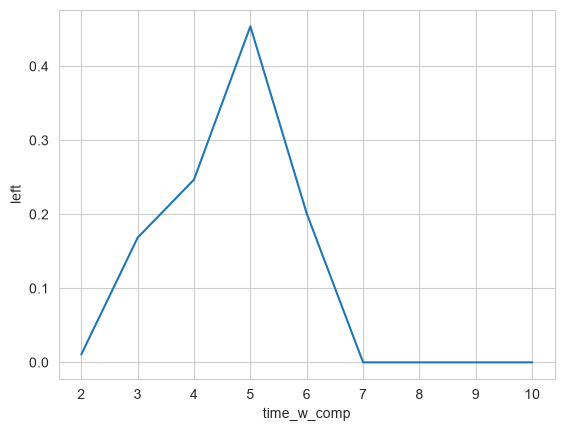

In [360]:
m_left2=df0.groupby('time_w_comp',as_index=False)['left'].mean()
sns.lineplot(data=m_left2,x='time_w_comp',y='left')

<Axes: xlabel='avg_monthly_hours', ylabel='eval'>

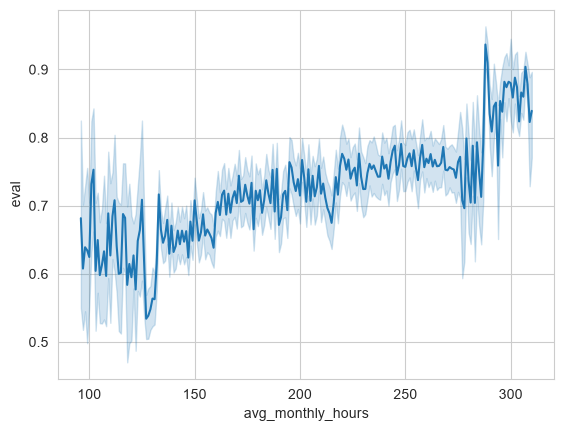

In [272]:
sns.lineplot(data=df0,x='avg_monthly_hours',y='eval')

In [273]:
df0['avg_monthly_hours'].corr(df0['eval']) ** 2

np.float64(0.07005420583006726)

In [274]:
df0['avg_monthly_hours'].corr(df0['satisfaction']) ** 2

np.float64(3.909194299326865e-05)

<Axes: xlabel='avg_monthly_hours', ylabel='eval'>

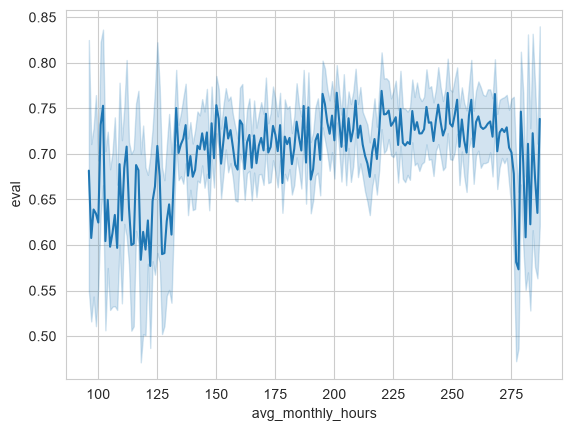

In [275]:
sns.lineplot(data=df0[df0['left']==0],x='avg_monthly_hours',y='eval')

<Axes: xlabel='avg_monthly_hours', ylabel='eval'>

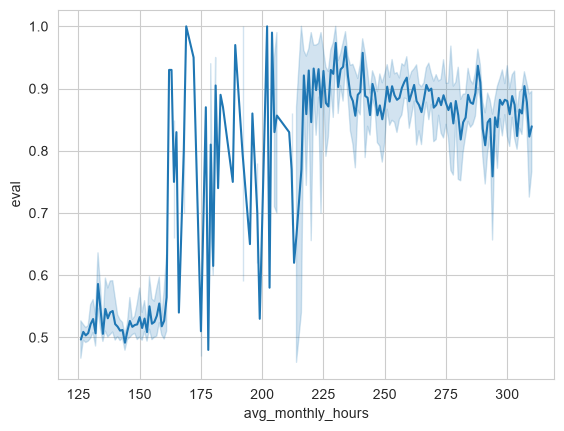

In [276]:
sns.lineplot(data=df0[df0['left']==1],x='avg_monthly_hours',y='eval')

In [277]:
# a lot of people staying didn't have high evals

<Axes: xlabel='num_projects', ylabel='avg_monthly_hours'>

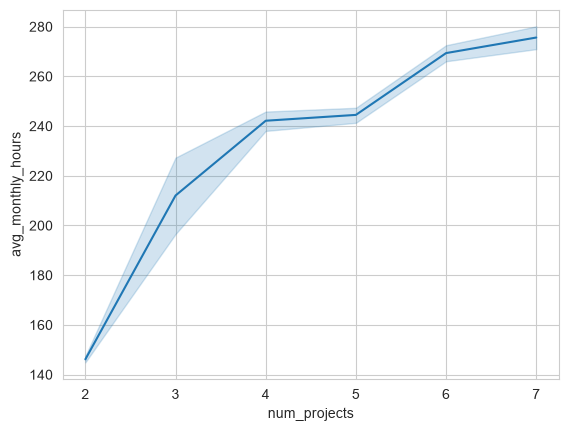

In [278]:
sns.lineplot(data=df0[df0['left']==1],x='num_projects',y='avg_monthly_hours')

<Axes: xlabel='avg_monthly_hours', ylabel='num_projects'>

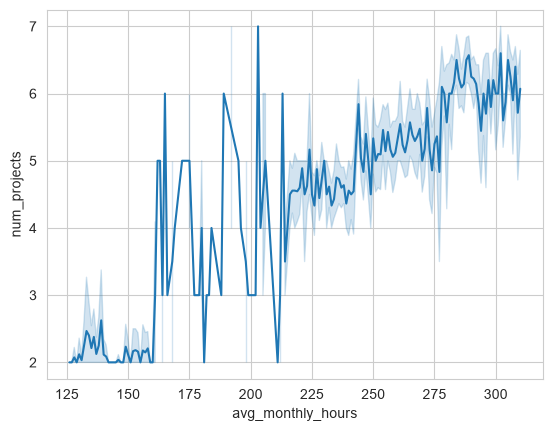

In [279]:
sns.lineplot(data=df0[df0['left']==1],x='avg_monthly_hours',y='num_projects')

In [280]:
#quantify with linear regression model

from sklearn.linear_model import LinearRegression
dfleft=df0[df0['left']==1]
Xlr=dfleft[['num_projects']]
ylr=dfleft['avg_monthly_hours']
lrmodel = LinearRegression()
lrmodel.fit(Xlr, ylr)
print("Intercept:", lrmodel.intercept_)
print("Coefficients:", lrmodel.coef_)
print("R-squared:", lrmodel.score(Xlr, ylr))

Intercept: 93.88034925872888
Coefficients: [29.4277321]
R-squared: 0.7610927830341057


In [281]:
#0.76 is not terribly high, but reasonable to leave out num_projects if already considering avg_monthly_hours, run test both ways

In [282]:
df0[df0['time_w_comp']>3].groupby('left')['num_projects'].value_counts(normalize=True)

left  num_projects
0     4               0.308021
      3               0.279501
      5               0.224599
      6               0.103387
      2               0.084492
1     6               0.330571
      5               0.305709
      4               0.195212
      7               0.129834
      3               0.023941
      2               0.014733
Name: proportion, dtype: float64

In [283]:
df0.dtypes

satisfaction              float64
eval                      float64
num_projects                int64
avg_monthly_hours           int64
time_w_comp                 int64
work_accident               int64
left                        int64
promotion_last_5_years      int64
dept                          str
salary                        str
dtype: object

In [284]:
#in terms or relation to retention, num_projects and salary nearly linear relation, time_w_comp and avg_monthly_hrs are related but not linear, have odd gaps (not due to samples missing in those ranges, which I checked). promotion_last_5_years and work_accident seem related. Very weak relation with dept, can probably discard.

In [285]:
#could use logistic regression, tree modelling

In [286]:
df0.dtypes

satisfaction              float64
eval                      float64
num_projects                int64
avg_monthly_hours           int64
time_w_comp                 int64
work_accident               int64
left                        int64
promotion_last_5_years      int64
dept                          str
salary                        str
dtype: object

In [287]:
# could just dummy variables, but dilutes effects. Not too worried about dept, but salary looks important
# df1 = pd.get_dummies(df0,columns=['dept','salary'])

In [288]:
df1=df0.copy()
df1.head()

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [289]:
#better to turn income into ordered encoding, e.g. 1,2,3
salary_encoding = {'low': 0, 'medium': 1, 'high': 2}
df1['salary'] = df1['salary'].map(salary_encoding)
df1['salary']

0        0
1        1
2        1
3        0
4        0
        ..
11986    2
11987    2
11988    2
11989    2
11990    0
Name: salary, Length: 11991, dtype: int64

In [290]:
#encode dept by average of left value for dept
#since we are concerned with left rate, numerically ordering dept by left rate won't dilute dept effect, and will preserve left effect on dept
#not really expecting it to effect much, but may as well see.
#double check all numbers unique
dept_left_df=df1.groupby('dept',as_index=False).mean().sort_values(by='left')[['dept','left']]
print(len(dept_left_df['dept'].unique()),len(dept_left_df['left'].unique()))

10 10


In [291]:
deptt_left_dict=dict(zip(dept_left_df['dept'],dept_left_df['left']))


In [292]:
df1['dept']=df1['dept'].map(deptt_left_dict)

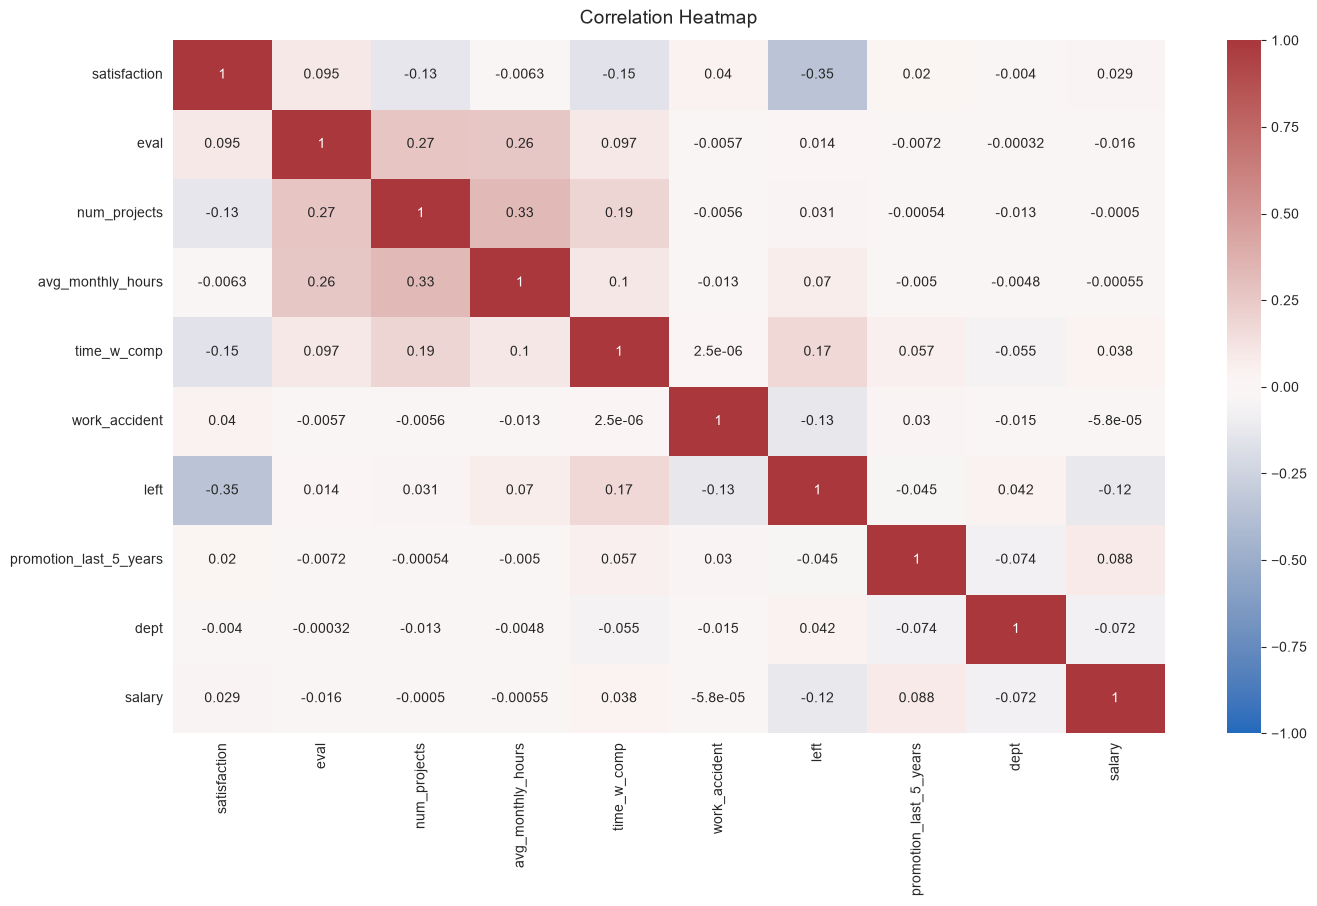

In [293]:
plt.figure(figsize=(16, 9))
heatmap = sns.heatmap(df1.corr(), vmin=-1, vmax=1, annot=True, cmap=sns.color_palette("vlag", as_cmap=True))
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':14}, pad=12);

In [294]:
y = df1['left']
X = df1.drop('left',axis=1)

In [295]:
X

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,promotion_last_5_years,dept,salary
0,0.38,0.53,2,157,3,0,0,0.169805,0
1,0.80,0.86,5,262,6,0,0,0.169805,1
2,0.11,0.88,7,272,4,0,0,0.169805,1
3,0.72,0.87,5,223,5,0,0,0.169805,0
4,0.37,0.52,2,159,3,0,0,0.169805,0
...,...,...,...,...,...,...,...,...,...
11986,0.90,0.55,3,259,10,1,1,0.119266,2
11987,0.74,0.95,5,266,10,0,1,0.119266,2
11988,0.85,0.54,3,185,10,0,1,0.119266,2
11989,0.33,0.65,3,172,10,0,1,0.166419,2


In [296]:
y

0        1
1        1
2        1
3        1
4        1
        ..
11986    0
11987    0
11988    0
11989    0
11990    0
Name: left, Length: 11991, dtype: int64

In [297]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state = 0)


In [298]:
cv_params = {'n_estimators' : [50,100], 
              'max_depth' : [10,50],        
              'min_samples_leaf' : [0.5,1], 
              'min_samples_split' : [0.001, 0.01],
              'max_features' : ["sqrt"], 
              'max_samples' : [.5,.9]}

In [299]:
rf = RandomForestClassifier(random_state=0)

In [300]:
#grid search guaranteed to find best combination of hyper-parameters within specified bounds
#use f1 (harmonic mean (heavily penalizes small values) of recall and precision)
rf_val = GridSearchCV(rf, cv_params, cv=5, refit='f1', n_jobs = -1)

In [301]:
%%time
rf_val.fit(X_train, y_train)

CPU times: total: 1.14 s
Wall time: 7.36 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 50], 'max_features': ['sqrt'], 'max_samples': [0.5, 0.9], 'min_samples_leaf': [0.5, 1], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"verbose verbose: i

In [302]:
rf_val.best_params_

{'max_depth': 50,
 'max_features': 'sqrt',
 'max_samples': 0.9,
 'min_samples_leaf': 1,
 'min_samples_split': 0.001,
 'n_estimators': 100}

In [303]:
ypred=rf_val.predict(X_test)

In [304]:
ac=accuracy_score(y_test, ypred)
pc=precision_score(y_test, ypred)
rec=recall_score(y_test, ypred)
f1=f1_score(y_test, ypred)

print('accuracy: ' +str(round(ac,4)),'precision: '+str(round(pc,4)),'recall: '+str(round(rec,4)),'f1: '+str(round(f1,4)))

accuracy: 0.9842 precision: 0.9918 recall: 0.9121 f1: 0.9503


In [305]:
rf_opt = RandomForestClassifier(max_depth= 50,
 max_features= 'sqrt',
 max_samples= 0.9,
 min_samples_leaf= 1,
 min_samples_split= 0.001,
 n_estimators= 50)

In [306]:
rf_opt.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",0.001
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",0.9
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numbe

In [307]:
y_pred = rf_opt.predict(X_test)

In [308]:
ac=accuracy_score(y_test, y_pred)
pc=precision_score(y_test, y_pred)
rec=recall_score(y_test, y_pred)
f1=f1_score(y_test, y_pred)

print('accuracy: ' +str(round(ac,4)),'precision: '+str(round(pc,4)),'recall: '+str(round(rec,4)),'f1: '+str(round(f1,4)))

accuracy: 0.9833 precision: 0.9891 recall: 0.9095 f1: 0.9476


In [309]:
rf_opt.estimators_

[DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=107614320),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=679404361),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=1024804001),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=433494313),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=1101491410),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=2114350380),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
                        min_samples_split=0.001, random_state=180686893),
 DecisionTreeClassifier(max_depth=50, max_features='sqrt',
       

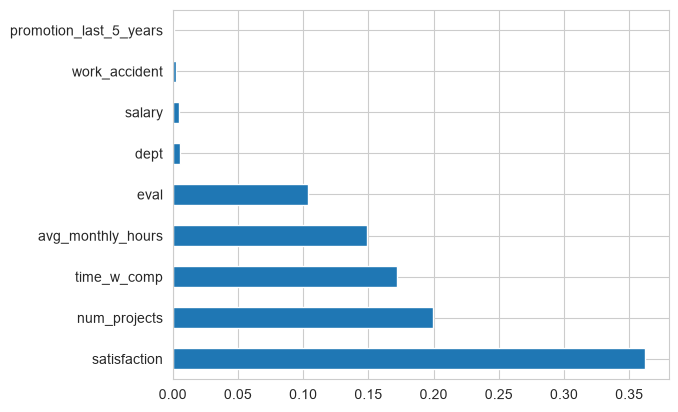

In [361]:
importances = rf_opt.feature_importances_
feat_importances = pd.Series(importances, index=X.columns)
feat_importances.nlargest(10).plot(kind="barh")
plt.show()

In [370]:
feat_importances

satisfaction              0.362163
eval                      0.103511
num_projects              0.199589
avg_monthly_hours         0.148739
time_w_comp               0.171859
work_accident             0.002840
promotion_last_5_years    0.000638
dept                      0.005701
salary                    0.004961
dtype: float64

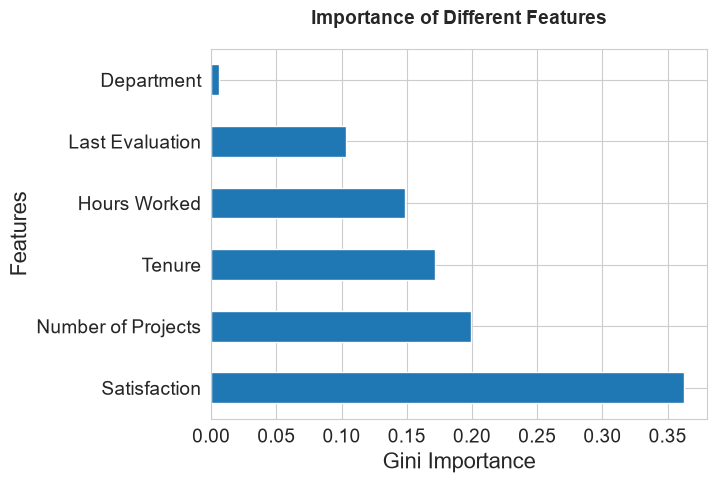

In [386]:
importances = rf_opt.feature_importances_
feat_importances = pd.Series(importances, index=X.columns).rename({'dept': 'Department', 'eval': 'Last Evaluation','avg_monthly_hours': 'Hours Worked', 'time_w_comp': 'Tenure', 'num_projects': 'Number of Projects', 'satisfaction': 'Satisfaction'})
feat_importances.nlargest(6).plot(kind="barh", fontsize=14)
plt.title("Importance of Different Features", fontsize=14, fontweight='bold', pad=18)
plt.xlabel("Gini Importance", fontsize=16)
plt.ylabel("Features", fontsize=16)
plt.savefig("ImportanceHist.pdf", bbox_inches="tight")
plt.show()

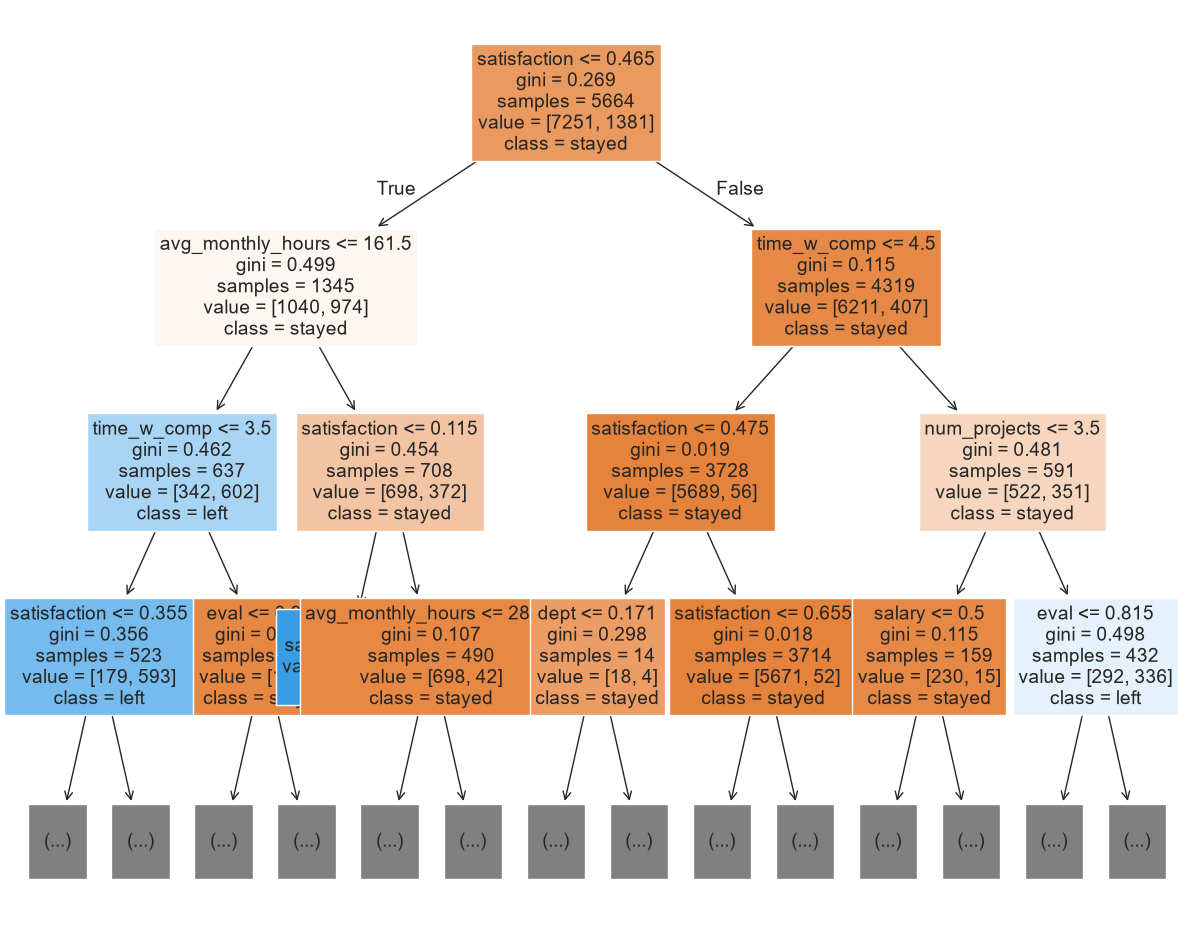

In [311]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15,12))
plot_tree(rf_opt.estimators_[0], max_depth=3, fontsize=14, feature_names=X.columns, 
          class_names={0:'stayed', 1:'left'}, filled=True);
plt.show()

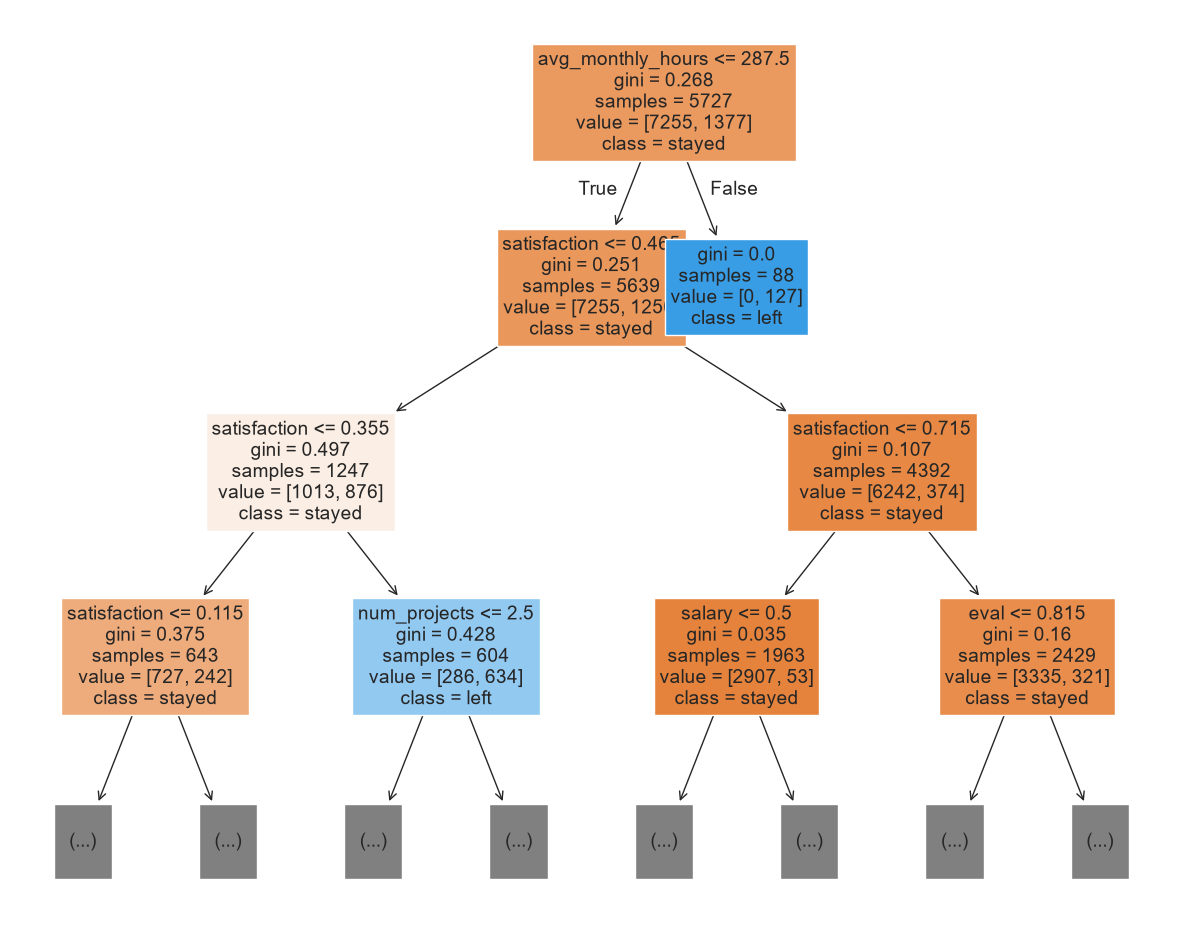

In [312]:
plt.figure(figsize=(15,12))
plot_tree(rf_opt.estimators_[1], max_depth=3, fontsize=14, feature_names=X.columns, 
          class_names={0:'stayed', 1:'left'}, filled=True);
plt.show()

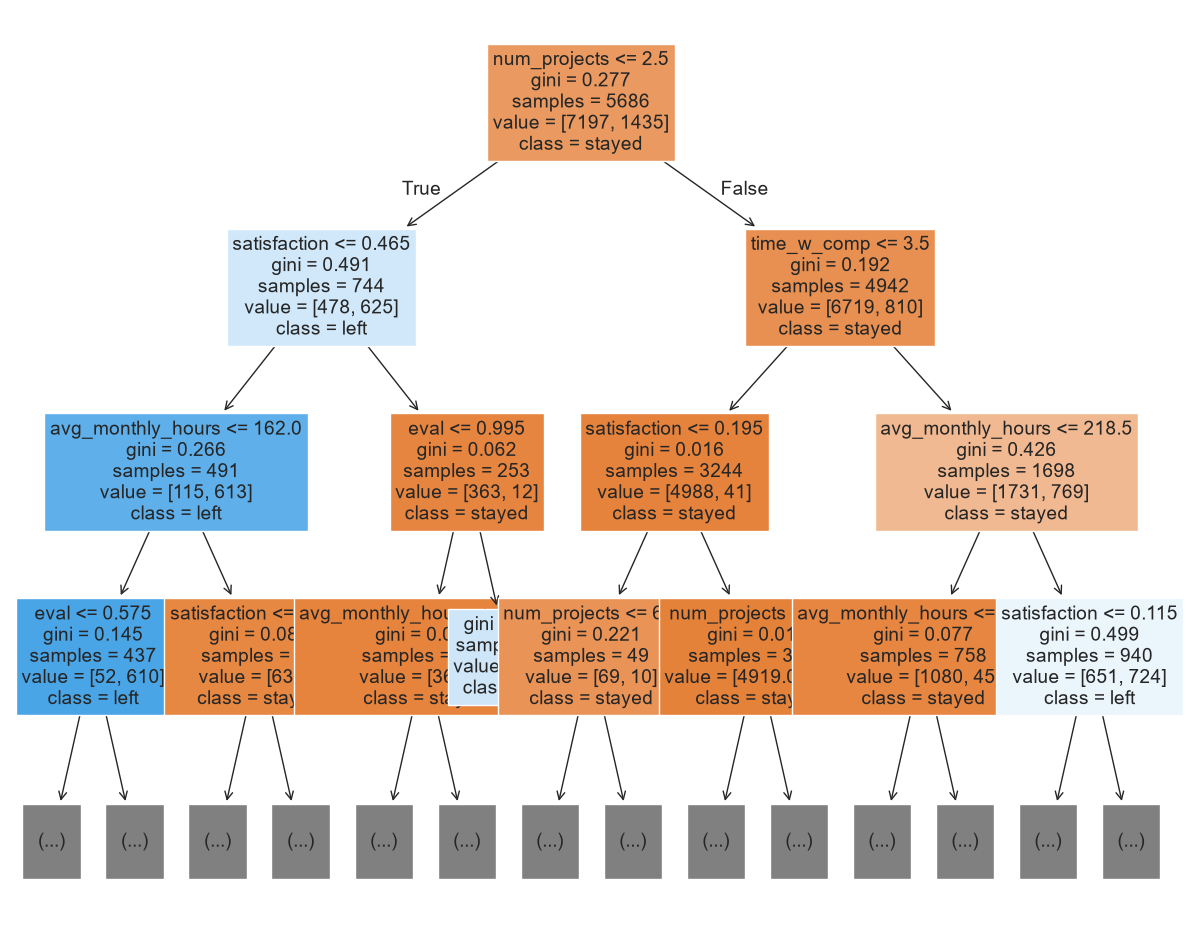

In [313]:
plt.figure(figsize=(15,12))
plot_tree(rf_opt.estimators_[2], max_depth=3, fontsize=14, feature_names=X.columns, 
          class_names={0:'stayed', 1:'left'}, filled=True);
plt.show()

In [314]:
#run again, but with no avg_monthly_hours or satisfaction

In [315]:
dflean=df1.copy()
dflean.head()

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
0,0.38,0.53,2,157,3,0,1,0,0.169805,0
1,0.80,0.86,5,262,6,0,1,0,0.169805,1
2,0.11,0.88,7,272,4,0,1,0,0.169805,1
3,0.72,0.87,5,223,5,0,1,0,0.169805,0
4,0.37,0.52,2,159,3,0,1,0,0.169805,0


In [316]:
dflean.drop(columns=['avg_monthly_hours','satisfaction'],inplace=True)
dflean.head()

,eval,num_projects,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
0,0.53,2,3,0,1,0,0.169805,0
1,0.86,5,6,0,1,0,0.169805,1
2,0.88,7,4,0,1,0,0.169805,1
3,0.87,5,5,0,1,0,0.169805,0
4,0.52,2,3,0,1,0,0.169805,0


In [317]:
ylean = dflean['left']
Xlean = dflean.drop('left',axis=1)

In [318]:
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xlean, ylean, test_size = 0.2, stratify=y, random_state = 0)

In [319]:
#use same cv_parameters as before
rfl = RandomForestClassifier(random_state=0)
#grid search guaranteed to find best combination of hyper-parameters within specified bounds
#use f1 (harmonic mean (heavily penalizes small values) of recall and precision)
rfl_val = GridSearchCV(rfl, cv_params, cv=5, refit='f1', n_jobs=-1)
rfl_val.fit(Xl_train, yl_train)

ypredl = rfl_val.predict(Xl_test)
acl = accuracy_score(yl_test, ypredl)
pcl = precision_score(yl_test, ypredl)
recl = recall_score(yl_test, ypredl)
f1l = f1_score(yl_test, ypredl)

print('for lean: '+'accuracy: ' + str(round(acl, 4)), 'precision: ' + str(round(pcl, 4)), 'recall: ' + str(round(recl, 4)),
      'f1: ' + str(round(f1l, 4)))
print('for normal: '+'accuracy: ' + str(round(ac, 4)), 'precision: ' + str(round(pc, 4)), 'recall: ' + str(round(rec, 4)),
      'f1: ' + str(round(f1, 4)))

for lean: accuracy: 0.9571 precision: 0.8772 recall: 0.8618 f1: 0.8695
for normal: accuracy: 0.9833 precision: 0.9891 recall: 0.9095 f1: 0.9476


In [320]:
rfl_val.best_params_

{'max_depth': 10,
 'max_features': 'sqrt',
 'max_samples': 0.5,
 'min_samples_leaf': 1,
 'min_samples_split': 0.001,
 'n_estimators': 100}

In [321]:
rfl_opt = RandomForestClassifier(max_depth= 10,
 max_features= 'sqrt',
 max_samples= 0.5,
 min_samples_leaf= 1,
 min_samples_split= 0.001,
 n_estimators= 100)
rfl_opt

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",0.001
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",0.5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [322]:
rfl_opt.fit(Xl_train, yl_train)
yl_pred = rfl_opt.predict(Xl_test)
acl = accuracy_score(yl_test, yl_pred)
pcl = precision_score(yl_test, yl_pred)
recl = recall_score(yl_test, yl_pred)
f1l = f1_score(yl_test, yl_pred)

print('accuracy: ' + str(round(acl, 4)), 'precision: ' + str(round(pcl, 4)), 'recall: ' + str(round(recl, 4)),
      'f1: ' + str(round(f1l, 4)))

accuracy: 0.9571 precision: 0.8753 recall: 0.8643 f1: 0.8698


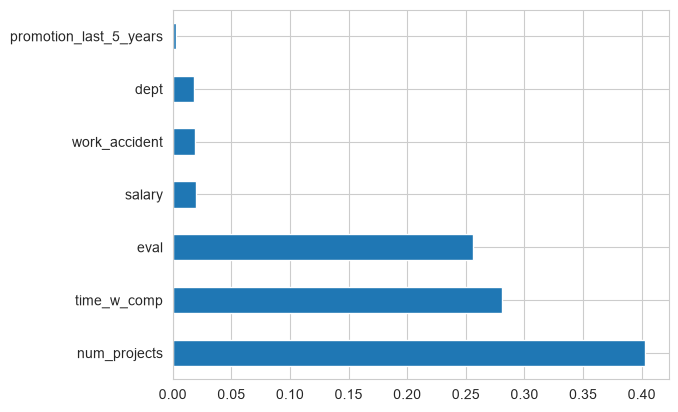

In [323]:
importancesl = rfl_opt.feature_importances_
feat_importancesl = pd.Series(importancesl, index=Xlean.columns)
feat_importancesl.nlargest(10).plot(kind="barh")
plt.show()

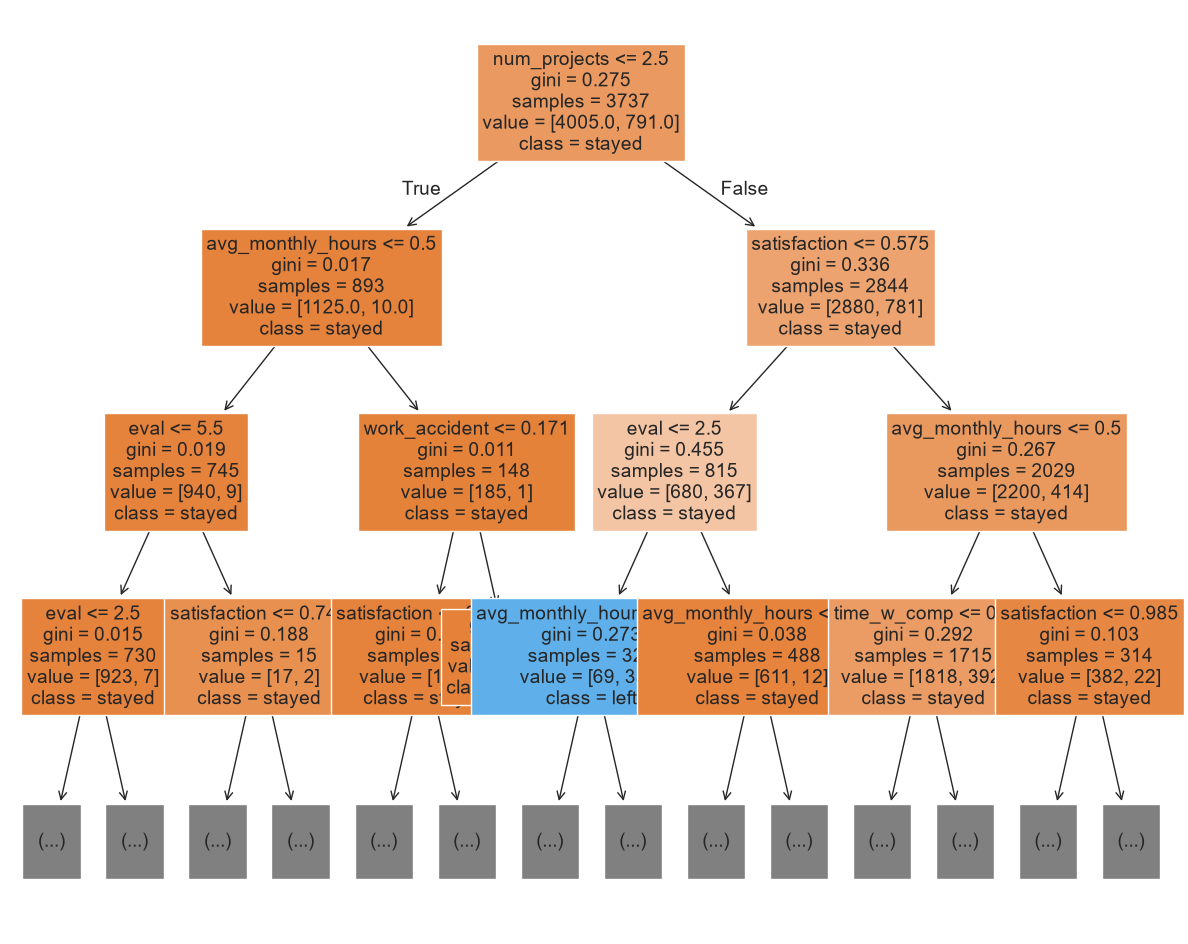

In [324]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(15, 12))
plot_tree(rfl_opt.estimators_[0], max_depth=3, fontsize=14, feature_names=X.columns,
          class_names={0: 'stayed', 1: 'left'}, filled=True);
plt.show()

<Axes: xlabel='time_w_comp'>

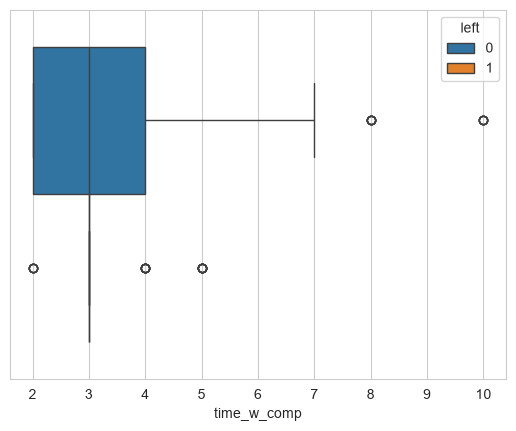

In [325]:
few_proj=df1[df1['num_projects']<3]
sns.boxplot(data=few_proj, x='time_w_comp',hue='left')

<Axes: xlabel='avg_monthly_hours'>

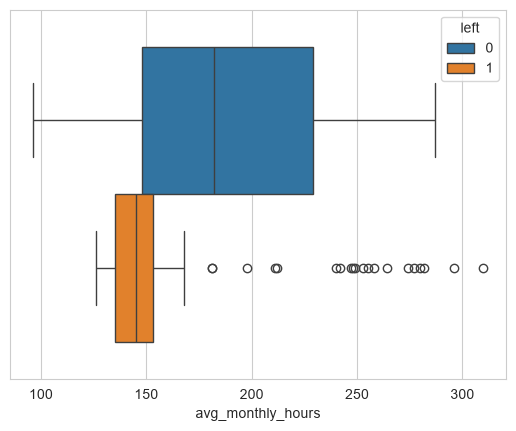

In [326]:
sns.boxplot(data=few_proj, x='avg_monthly_hours',hue='left')

<Axes: xlabel='time_w_comp'>

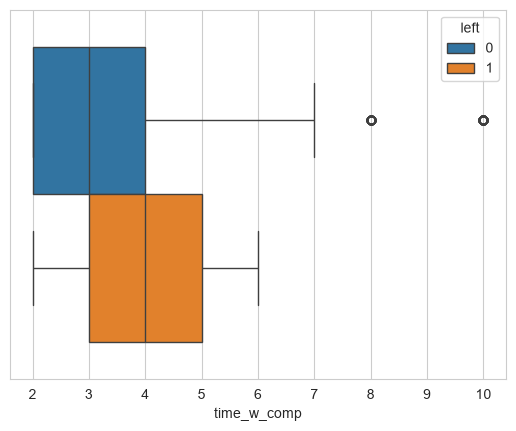

In [327]:
sns.boxplot(data=df1, x='time_w_comp',hue='left')

In [328]:
few_proj.describe()

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
count,1582.000000,1582.000000,1582.0,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000,1582.000000
mean,0.499071,0.584640,2.0,164.812263,3.186473,0.111252,0.541719,0.012010,0.166820,0.522124
std,0.175465,0.145815,0.0,42.224733,0.971442,0.314543,0.498414,0.108965,0.014451,0.611261
min,0.100000,0.360000,2.0,96.000000,2.000000,0.000000,0.000000,0.000000,0.119266,0.000000
25%,0.390000,0.490000,2.0,137.000000,3.000000,0.000000,0.000000,0.000000,0.166419,0.000000
50%,0.430000,0.540000,2.0,151.000000,3.000000,0.000000,1.000000,0.000000,0.169805,0.000000
75%,0.577500,0.640000,2.0,179.000000,3.000000,0.000000,1.000000,0.000000,0.173797,1.000000
max,1.000000,1.000000,2.0,310.000000,10.000000,1.000000,1.000000,1.000000,0.188020,2.000000


In [329]:
few_proj[few_proj['left']==1].describe()

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
count,857.000000,857.000000,857.0,857.000000,857.000000,857.000000,857.0,857.000000,857.000000,857.000000
mean,0.412345,0.517888,2.0,146.143524,3.022170,0.052509,1.0,0.005834,0.167823,0.429405
std,0.051781,0.063438,0.0,19.438837,0.228206,0.223181,0.0,0.076204,0.013452,0.546846
min,0.100000,0.450000,2.0,126.000000,2.000000,0.000000,1.0,0.000000,0.119266,0.000000
25%,0.380000,0.480000,2.0,135.000000,3.000000,0.000000,1.0,0.000000,0.166419,0.000000
50%,0.410000,0.510000,2.0,145.000000,3.000000,0.000000,1.0,0.000000,0.169805,0.000000
75%,0.440000,0.540000,2.0,153.000000,3.000000,0.000000,1.0,0.000000,0.173797,1.000000
max,0.890000,1.000000,2.0,310.000000,5.000000,1.000000,1.0,1.000000,0.188020,2.000000


In [330]:
#out of 857 people who didn't take many projects and left, almost all had been working with company about three years
#almost all people who only took 2 projects and left were working less than 40hrs/week on avg, while those who stayed were working more -> people working less and leaving had already "checked out"

In [331]:
more_proj=df1[df1['num_projects']>2]

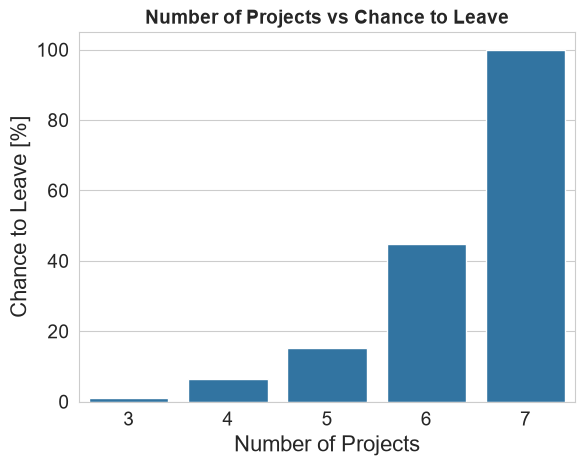

In [390]:
more_proj_2=more_proj.copy()
more_proj_2['left']=more_proj['left']*100
m_left_mp=more_proj_2.groupby('num_projects',as_index=False)['left'].mean()
sns.barplot(data=m_left_mp,x='num_projects',y='left')
plt.tick_params(labelsize=14)
plt.title("Number of Projects vs Chance to Leave", fontsize=14, fontweight="bold")
plt.xlabel("Number of Projects", fontsize=16)
plt.ylabel("Chance to Leave [%]", fontsize=16)
plt.savefig("numProjVsLeave.pdf", bbox_inches="tight")

In [333]:
more_proj

,satisfaction,eval,num_projects,avg_monthly_hours,time_w_comp,work_accident,left,promotion_last_5_years,dept,salary
1,0.80,0.86,5,262,6,0,1,0,0.169805,1
2,0.11,0.88,7,272,4,0,1,0,0.169805,1
3,0.72,0.87,5,223,5,0,1,0,0.169805,0
6,0.10,0.77,6,247,4,0,1,0,0.169805,0
7,0.92,0.85,5,259,5,0,1,0,0.169805,0
...,...,...,...,...,...,...,...,...,...,...
11986,0.90,0.55,3,259,10,1,0,1,0.119266,2
11987,0.74,0.95,5,266,10,0,0,1,0.119266,2
11988,0.85,0.54,3,185,10,0,0,1,0.119266,2
11989,0.33,0.65,3,172,10,0,0,1,0.166419,2


In [334]:
#do logistic regression
#remove outliers

In [335]:
percentile25 = more_proj['time_w_comp'].quantile(0.25)

percentile75 = more_proj['time_w_comp'].quantile(0.75)
iqr = percentile75 - percentile25

upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr

more_proj_log = more_proj[(more_proj['time_w_comp'] >= lower_limit) & (more_proj['time_w_comp'] <= upper_limit)]

In [336]:
#X_mp=more_proj_log.drop('left',axis=1,inplace=False)
#select most important columns from random forrest model
X_mp=more_proj_log[['avg_monthly_hours','num_projects','time_w_comp','eval']]
y_mp=more_proj_log['left']

In [337]:
X_train_mp, X_test_mp, y_train_mp, y_test_mp = train_test_split(X_mp, y_mp, test_size=0.2, stratify=y_mp, random_state=0)

In [338]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

scaler = StandardScaler()
X_train_scaled_mp = scaler.fit_transform(X_train_mp)
X_test_scaled_mp = scaler.transform(X_test_mp)

model_mp = LogisticRegression(random_state=0)
model_mp.fit(X_train_scaled_mp, y_train_mp)

y_pred_mp = model_mp.predict(X_test_scaled_mp)

print("Accuracy:", accuracy_score(y_test_mp, y_pred_mp))
print("\nClassification Report:\n", classification_report(y_test_mp, y_pred_mp))

Accuracy: 0.9516365412799218

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97      1820
           1       0.83      0.70      0.76       227

    accuracy                           0.95      2047
   macro avg       0.90      0.84      0.87      2047
weighted avg       0.95      0.95      0.95      2047



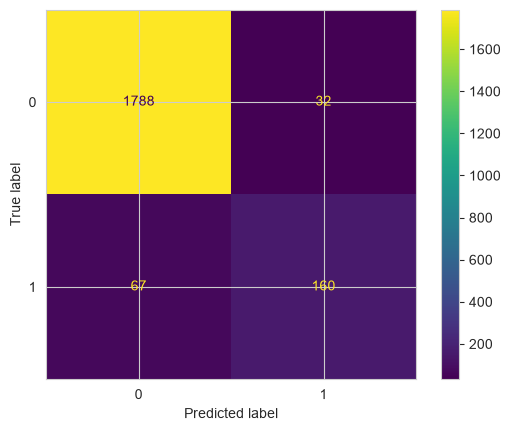

In [339]:
cm = confusion_matrix(y_test_mp, y_pred_mp, labels=model_mp.classes_)
log_disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=model_mp.classes_)
log_disp.plot(values_format='')
plt.show()

In [340]:
more_proj_log['left'].value_counts(normalize=True)

left
0    0.889171
1    0.110829
Name: proportion, dtype: float64

In [341]:
#redo without discounting low projects

<Axes: xlabel='num_projects', ylabel='left'>

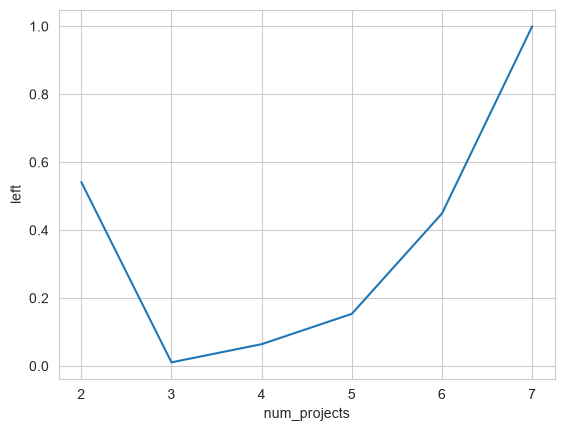

In [342]:
df1_proj=df1.groupby('num_projects',as_index=False)['left'].mean()
sns.lineplot(data=df1_proj,x='num_projects',y='left')

In [343]:
percentile25_all = df1['time_w_comp'].quantile(0.25)
percentile75_all = df1['time_w_comp'].quantile(0.75)
iqr_all = percentile75_all - percentile25_all

upper_limit_all = percentile75_all + 1.5 * iqr_all
lower_limit_all = percentile25_all - 1.5 * iqr_all

df1_log = df1[(df1['time_w_comp'] >= lower_limit) & (df1['time_w_comp'] <= upper_limit)]

Accuracy: 0.8166031342651419

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.98      0.90      1963
           1       0.00      0.00      0.00       398

    accuracy                           0.82      2361
   macro avg       0.41      0.49      0.45      2361
weighted avg       0.69      0.82      0.75      2361



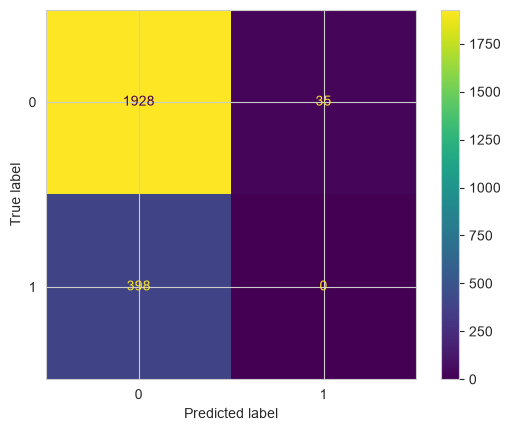

In [344]:
#select most important columns from random forrest model
X_df1_log = df1_log[['avg_monthly_hours', 'num_projects', 'time_w_comp', 'eval']]
y_df1_log = df1_log['left']
X_train_df1_log, X_test_df1_log, y_train_df1_log, y_test_df1_log = train_test_split(X_df1_log, y_df1_log, test_size=0.2, stratify=y_df1_log,
                                                                random_state=0)

scaler = StandardScaler()
X_train_scaled_df1_log = scaler.fit_transform(X_train_df1_log)
X_test_scaled_df1_log = scaler.transform(X_test_df1_log)

model_df1_log = LogisticRegression(random_state=0)
model_df1_log.fit(X_train_scaled_df1_log, y_train_df1_log)

y_pred_df1_log = model_df1_log.predict(X_test_scaled_df1_log)

print("Accuracy:", accuracy_score(y_test_df1_log, y_pred_df1_log))
print("\nClassification Report:\n", classification_report(y_test_df1_log, y_pred_df1_log))
cm_df1_log = confusion_matrix(y_test_df1_log, y_pred_df1_log, labels=model_df1_log.classes_)
log_disp = ConfusionMatrixDisplay(confusion_matrix=cm_df1_log,
                                  display_labels=model_df1_log.classes_)
log_disp.plot(values_format='')
plt.show()

In [ ]:
#including low-project individuals ruins model

In [345]:
df1_log['left'].value_counts(normalize=True)

left
0    0.831314
1    0.168686
Name: proportion, dtype: float64

Accuracy: 0.9032730825598436

Classification Report:
               precision    recall  f1-score   support

           0       0.90      1.00      0.95      1820
           1       1.00      0.13      0.23       227

    accuracy                           0.90      2047
   macro avg       0.95      0.56      0.59      2047
weighted avg       0.91      0.90      0.87      2047



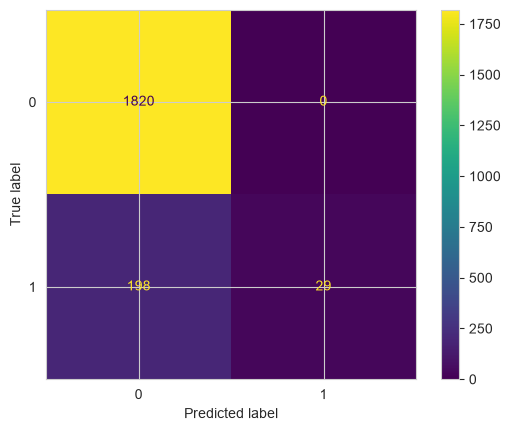

In [346]:
#only test num_projects, for sake of making recomendation
X_p = more_proj_log[['num_projects']]
y_p = more_proj_log['left']
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_p, y_p, test_size=0.2, stratify=y_p,

scaler = StandardScaler()
X_train_scaled_p = scaler.fit_transform(X_train_p)
X_test_scaled_p = scaler.transform(X_test_p)

model_p = LogisticRegression(random_state=0)
model_p.fit(X_train_scaled_p, y_train_p)

y_pred_p = model_p.predict(X_test_scaled_p)

print("Accuracy:", accuracy_score(y_test_p, y_pred_p))
print("\nClassification Report:\n", classification_report(y_test_p, y_pred_p))
cm = confusion_matrix(y_test_p, y_pred_p, labels=model_p.classes_)
log_disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=model_p.classes_)
log_disp.plot(values_format='')
plt.show()

In [348]:
##Conclusions

In [349]:
#very good model metrics/evals: accuracy: 0.9842 precision: 0.9918 recall: 0.9121 f1: 0.9503
#shows satisfaction best predictor of leaving or not (obvious from onset)
#then num_projects and avg_monthly_hours, suggesting a lot of people leaving due to burnout
#then time_w_company, if you can retain employees for longer than 5 years, drastically improve liklihood of maintaining them. Highest amount of employees leaving around 3 year mark.
#finally, highest evals were most likely to leave, again suggesting burnout culture

#as recommendation, would suggest cutting employee projects to no more than 5
#of employees who were with company for over 3 years (valuable employees with lots of experience), 76% who left had 5 or more projects